# Field Shift — 5-County Iowa Data Ingestion (Google Colab)

**Purpose:** build a compact, geographically stratified Iowa pilot dataset for the NASA Space Apps *Field Shift* challenge.

## Selected counties

| County | FIPS | SSURGO area | Representative point | Sampling role |
|---|---:|---|---|---|
| Lyon | 19119 | IA119 | Rock Rapids | Northwest Iowa Plains; generally higher and drier |
| Allamakee | 19005 | IA005 | Waukon | Paleozoic Plateau; rugged, bedrock-influenced terrain |
| Story | 19169 | IA169 | Nevada | Des Moines Lobe / central Iowa row-crop setting |
| Decatur | 19053 | IA053 | Leon | Southern Iowa Drift Plain |
| Lee | 19111 | IA111 | Fort Madison | Southern Iowa Drift Plain uplands plus Mississippi/tributary alluvial valleys |

The five counties intentionally span the state rather than treating Story County as the only training area. This is a **pilot sample**, not proof that a model generalises to all U.S. farms.

## Data sources in this notebook

1. **USDA CDL:** annual crop-type maps, downloaded county-by-county for 2015–2025. The notebook also creates a small, same-location sampled crop-history table. The 2024–2025 10 m products are resampled to the 2015 county grid (nearest neighbour) before comparing years.
2. **NRCS SSURGO:** selected soil component and 0–30 cm horizon attributes, queried separately for each county soil-survey area.
3. **NASA POWER:** daily agroclimate series at a representative county-seat point for each county. This is a point proxy, not a field-level or county-average measurement. POWER's meteorological grid is relatively coarse, so do not interpret the point series as exact field weather.
4. **USDA NASS Quick Stats:** county-level historic yields for selected crops, where reported.
5. **USDA AMS Market News:** Iowa Daily Cash Grain Bids (report 2850), downloaded once as a **statewide / reporting-market benchmark**, not falsely assigned as a precise price for each county.

## Important modelling safeguards

- Keep `county_fips` and `county_name` on every record. Do not merge spatially distinct counties into anonymous rows.
- Hold out at least one **entire county** for spatial validation. Do not rely only on random pixel splits.
- CDL class labels are remotely sensed classifications, not perfect ground truth. The notebook exports class proportions and sampled point sequences for inspection.
- SSURGO is map-unit/component information, not a lab test for each sampled CDL pixel. Do not join a county-average soil value to every pixel and call it field-level soil truth.
- LSTM is not trained in this notebook. First validate coverage, missingness, crop sequence lengths, spatial alignment, and soil/yield availability.
- AMS grain bids are market signals. Revenue estimation requires matching a crop's yield to a relevant price and is **gross revenue**, not profit.

**Expected first-run deliverables:** county-year crop class summaries; sampled annual crop sequences; SSURGO tables; NASA POWER time series; NASS yield records; optional AMS market prices.

## 1) Install libraries

Run this cell first in a fresh Colab runtime.

In [ ]:
!pip -q install requests pandas numpy rasterio

## 2) Imports and final 5-county configuration

The coordinates below are representative county-seat points used only for NASA POWER point queries. Replace them with actual field coordinates when a farmer/field polygon is available.

In [ ]:
from pathlib import Path
import os, re, json, time, zipfile, warnings
import requests
import pandas as pd
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling
from getpass import getpass
from IPython.display import display

COUNTIES = pd.DataFrame([
    {"county_name":"Lyon", "state_name":"Iowa", "state_alpha":"IA", "state_fips":"19", "county_fips":"19119", "ssurgo_areasymbol":"IA119", "representative_place":"Rock Rapids", "latitude":43.4272803, "longitude":-96.1661938, "broad_region":"Northwest Iowa", "landform_context":"Northwest Iowa Plains"},
    {"county_name":"Allamakee", "state_name":"Iowa", "state_alpha":"IA", "state_fips":"19", "county_fips":"19005", "ssurgo_areasymbol":"IA005", "representative_place":"Waukon", "latitude":43.2694200, "longitude":-91.4757000, "broad_region":"Northeast Iowa", "landform_context":"Paleozoic Plateau"},
    {"county_name":"Story", "state_name":"Iowa", "state_alpha":"IA", "state_fips":"19", "county_fips":"19169", "ssurgo_areasymbol":"IA169", "representative_place":"Nevada", "latitude":42.0211100, "longitude":-93.4652800, "broad_region":"Central Iowa", "landform_context":"Des Moines Lobe"},
    {"county_name":"Decatur", "state_name":"Iowa", "state_alpha":"IA", "state_fips":"19", "county_fips":"19053", "ssurgo_areasymbol":"IA053", "representative_place":"Leon", "latitude":40.7400000, "longitude":-93.7463900, "broad_region":"South-central Iowa", "landform_context":"Southern Iowa Drift Plain"},
    {"county_name":"Lee", "state_name":"Iowa", "state_alpha":"IA", "state_fips":"19", "county_fips":"19111", "ssurgo_areasymbol":"IA111", "representative_place":"Fort Madison", "latitude":40.6297632, "longitude":-91.3151506, "broad_region":"Southeast Iowa", "landform_context":"Southern Iowa Drift Plain and Mississippi River alluvial valleys"},
])

# Historical crop layers: 2015-2025 (2026 season is not treated as a completed annual layer).
START_YEAR = 2015
END_YEAR = 2025
CDL_YEARS = list(range(START_YEAR, END_YEAR + 1))
MAX_PIXELS_PER_COUNTY = 4000  # keeps the sampled sequence table compact
RANDOM_SEED = 42

# Crops to query in NASS county-yield records; missing county/crop/year records are left missing.
NASS_CROPS = ["CORN", "SOYBEANS", "WHEAT", "OATS", "SORGHUM"]

PROJECT_DIR = Path('/content/field_shift_data')
RAW_DIR = PROJECT_DIR / 'raw'
PROCESSED_DIR = PROJECT_DIR / 'processed'
CDL_DIR = RAW_DIR / 'cdl'
SSURGO_DIR = RAW_DIR / 'ssurgo'
POWER_DIR = RAW_DIR / 'nasa_power'
for folder in [RAW_DIR, PROCESSED_DIR, CDL_DIR, SSURGO_DIR, POWER_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

COUNTIES.to_csv(PROCESSED_DIR / 'county_configuration.csv', index=False)
display(COUNTIES)
print(f"Configured {len(COUNTIES)} counties | years {START_YEAR}-{END_YEAR}")
print('Project folder:', PROJECT_DIR)

,county_name,state_name,state_alpha,state_fips,county_fips,ssurgo_areasymbol,representative_place,latitude,longitude,broad_region,landform_context
0,Lyon,Iowa,IA,19,19119,IA119,Rock Rapids,43.427280,-96.166194,Northwest Iowa,Northwest Iowa Plains
1,Allamakee,Iowa,IA,19,19005,IA005,Waukon,43.269420,-91.475700,Northeast Iowa,Paleozoic Plateau
2,Story,Iowa,IA,19,19169,IA169,Nevada,42.021110,-93.465280,Central Iowa,Des Moines Lobe
3,Decatur,Iowa,IA,19,19053,IA053,Leon,40.740000,-93.746390,South-central Iowa,Southern Iowa Drift Plain
4,Lee,Iowa,IA,19,19111,IA111,Fort Madison,40.629763,-91.315151,Southeast Iowa,Southern Iowa Drift Plain and Mississippi Rive...


Configured 5 counties | years 2015-2025
Project folder: /content/field_shift_data


## 3) NASA POWER — daily climate series for all five counties

One point request per county; this gives five labelled time series. NASA POWER daily data are available from 1981 to near-real-time. A POWER point is a representative grid-cell value, not a precise field observation.

In [ ]:
POWER_URL = 'https://power.larc.nasa.gov/api/temporal/daily/point'
POWER_PARAMETERS = 'T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,ALLSKY_SFC_SW_DWN'

power_frames = []
power_failures = []

for row in COUNTIES.to_dict('records'):
    county = row['county_name']
    params = {
        'parameters': POWER_PARAMETERS,
        'community': 'AG',
        'longitude': row['longitude'],
        'latitude': row['latitude'],
        'start': f'{START_YEAR}0101',
        'end': f'{END_YEAR}1231',
        'format': 'JSON',
        'time-standard': 'UTC'
    }
    try:
        response = requests.get(POWER_URL, params=params, timeout=120)
        response.raise_for_status()
        payload = response.json()
        (POWER_DIR / f'nasa_power_{county.lower()}_raw.json').write_text(json.dumps(payload))
        param_dict = payload['properties']['parameter']
        df = pd.DataFrame(param_dict)
        df.index = pd.to_datetime(df.index, format='%Y%m%d', errors='coerce')
        df.index.name = 'date'
        df = df.replace(-999, np.nan).reset_index()
        df['county_name'] = county
        df['county_fips'] = row['county_fips']
        df['representative_place'] = row['representative_place']
        df['latitude'] = row['latitude']
        df['longitude'] = row['longitude']
        power_frames.append(df)
        df.to_csv(POWER_DIR / f'nasa_power_{county.lower()}_daily.csv', index=False)
        print(f"{county}: {len(df):,} daily records")
        time.sleep(0.3)
    except Exception as exc:
        power_failures.append((county, str(exc)))
        print(f"WARNING — NASA POWER failed for {county}: {exc}")

power_all = pd.concat(power_frames, ignore_index=True) if power_frames else pd.DataFrame()
if not power_all.empty:
    power_all.to_csv(PROCESSED_DIR / 'nasa_power_daily_all_counties.csv', index=False)
    display(power_all.groupby('county_name').agg(rows=('date','size'), start=('date','min'), end=('date','max')))
print('POWER failures:', power_failures)

Lyon: 4,018 daily records
Allamakee: 4,018 daily records
Story: 4,018 daily records
Decatur: 4,018 daily records
Lee: 4,018 daily records


,rows,start,end
county_name,,,
Allamakee,4018,2015-01-01,2025-12-31
Decatur,4018,2015-01-01,2025-12-31
Lee,4018,2015-01-01,2025-12-31
Lyon,4018,2015-01-01,2025-12-31
Story,4018,2015-01-01,2025-12-31


POWER failures: []


## 4) USDA Cropland Data Layer (CDL) — download county-by-county

The notebook requests one GeoTIFF per county per year rather than a national raster. If a download fails, the failure is recorded; no missing year is silently replaced.

In [ ]:
CDL_SERVICE = 'https://nassgeodata.gmu.edu/axis2/services/CDLService/GetCDLFile'


def request_cdl_tif(year: int, county_fips: str, county_name: str):
    out_path = CDL_DIR / f'CDL_{year}_{county_fips}_{county_name}.tif'
    if out_path.exists() and out_path.stat().st_size > 100_000:
        print(f'{county_name} {year}: already downloaded ({out_path.stat().st_size/1e6:.1f} MB)')
        return out_path

    resp = requests.get(CDL_SERVICE, params={'year': year, 'fips': county_fips}, timeout=120)
    resp.raise_for_status()
    return_url = None
    try:
        root = __import__('xml.etree.ElementTree', fromlist=['ElementTree']).fromstring(resp.content)
        for elem in root.iter():
            if elem.tag.lower().endswith('returnurl') and elem.text:
                return_url = elem.text.strip()
                break
    except Exception:
        pass
    if not return_url:
        match = re.search(r'https?://[^\s<>\"\']+\.tif(?:\?[^\s<>\"\']*)?', resp.text, flags=re.I)
        if match:
            return_url = match.group(0)
    if not return_url:
        raise RuntimeError(f'Could not parse CDL download URL. Response begins: {resp.text[:400]}')

    with requests.get(return_url, stream=True, timeout=240) as dl:
        dl.raise_for_status()
        with open(out_path, 'wb') as output:
            for chunk in dl.iter_content(chunk_size=1024*1024):
                if chunk:
                    output.write(chunk)
    if out_path.stat().st_size < 100_000:
        raise RuntimeError('Downloaded CDL file is unexpectedly small; inspect the response.')
    print(f'{county_name} {year}: saved {out_path.name} ({out_path.stat().st_size/1e6:.1f} MB)')
    return out_path

cdl_paths = {}
cdl_failures = []
for row in COUNTIES.to_dict('records'):
    name, fips = row['county_name'], row['county_fips']
    cdl_paths[name] = {}
    for year in CDL_YEARS:
        try:
            cdl_paths[name][year] = request_cdl_tif(year, fips, name)
            time.sleep(0.25)
        except Exception as exc:
            cdl_failures.append((name, year, str(exc)))
            print(f'WARNING — {name} {year} failed: {exc}')

print('CDL downloaded:', sum(len(v) for v in cdl_paths.values()), 'of', len(COUNTIES)*len(CDL_YEARS))
print('CDL failures:', cdl_failures)

Lyon 2015: already downloaded (1.8 MB)
Lyon 2016: already downloaded (1.8 MB)
Lyon 2017: already downloaded (1.8 MB)
Lyon 2018: already downloaded (1.8 MB)
Lyon 2019: already downloaded (1.8 MB)
Lyon 2020: already downloaded (1.8 MB)
Lyon 2021: already downloaded (1.8 MB)
Lyon 2022: already downloaded (1.8 MB)
Lyon 2023: already downloaded (1.8 MB)
Lyon 2024: already downloaded (1.8 MB)
Lyon 2025: already downloaded (1.8 MB)
Allamakee 2015: already downloaded (2.5 MB)
Allamakee 2016: already downloaded (2.5 MB)
Allamakee 2017: already downloaded (2.5 MB)
Allamakee 2018: already downloaded (2.5 MB)
Allamakee 2019: already downloaded (2.5 MB)
Allamakee 2020: saved CDL_2020_19005_Allamakee.tif (2.5 MB)
Allamakee 2021: already downloaded (2.5 MB)
Allamakee 2022: already downloaded (2.5 MB)
Allamakee 2023: already downloaded (2.5 MB)
Allamakee 2024: already downloaded (2.5 MB)
Allamakee 2025: already downloaded (2.5 MB)
Story 2015: already downloaded (1.7 MB)
Story 2016: already downloaded 

In [ ]:
# Retry only the four failed CDL downloads

retry_targets = [
    ("Lyon", 2015),
    ("Lyon", 2016),
    ("Lyon", 2017),
    ("Lee", 2018)
]

for county, year in retry_targets:

    row = COUNTIES[
        COUNTIES["county_name"] == county
    ].iloc[0]

    fips = str(row["county_fips"])

    filename = f"CDL_{year}_{fips}_{county}.tif"
    path = CDL_DIR / filename

    # Remove any incomplete file before retrying
    if path.exists():
        path.unlink()

    success = False

    for attempt in range(1, 4):
        try:
            print(
                f"Retrying {county} {year} "
                f"(Attempt {attempt}/3)"
            )

            result = request_cdl_tif(
                year, fips, county
            )

            cdl_paths.setdefault(county, {})[year] = result

            success = True
            break

        except Exception as error:
            print("Retry failed:", error)
            time.sleep(10 * attempt)

    if not success:
        print(f"Still missing: {county} {year}")

# Verify all downloaded files

missing = [
    (county, year)
    for county in COUNTIES["county_name"]
    for year in CDL_YEARS
    if year not in cdl_paths.get(county, {})
]

print("\nRemaining missing files:", missing)

downloaded = sum(
    len(years) for years in cdl_paths.values()
)

print(f"CDL downloaded: {downloaded}/55")

Retrying Lyon 2015 (Attempt 1/3)
Lyon 2015: saved CDL_2015_19119_Lyon.tif (1.8 MB)
Retrying Lyon 2016 (Attempt 1/3)
Lyon 2016: saved CDL_2016_19119_Lyon.tif (1.8 MB)
Retrying Lyon 2017 (Attempt 1/3)
Lyon 2017: saved CDL_2017_19119_Lyon.tif (1.8 MB)
Retrying Lee 2018 (Attempt 1/3)
Lee 2018: saved CDL_2018_19111_Lee.tif (2.8 MB)

Remaining missing files: []
CDL downloaded: 55/55


## 5) CDL audit + small same-location annual crop-history sample

This step is important for rotation modelling. For each county, it uses the earliest successfully downloaded CDL raster as a common 30 m reference grid, aligns each year to that grid using nearest-neighbour resampling, and samples up to 4,000 agricultural pixels. The output keeps the same sampled pixel locations across years for that county.

**Caution:** CDL 2024–2025 are higher-resolution layers than earlier years; they are resampled here to the reference grid to make a consistent prototype table. This is an analytical harmonisation choice, not a claim that all annual products have identical source resolution or classification accuracy.

In [ ]:
# Common CDL classes frequently relevant to Iowa rotations. Unknown codes remain labelled as Code_<n>.
CDL_NAMES = {
    1:'Corn', 2:'Cotton', 3:'Rice', 4:'Sorghum', 5:'Soybeans', 21:'Barley',
    22:'Durum Wheat', 23:'Spring Wheat', 24:'Winter Wheat', 25:'Other Small Grains',
    26:'Double Crop Winter Wheat/Soybeans', 27:'Rye', 28:'Oats', 29:'Millet',
    36:'Alfalfa', 37:'Other Hay/Non-Alfalfa', 38:'Camelina', 42:'Dry Beans',
    52:'Lentils', 53:'Peas', 58:'Clover/Wildflowers', 59:'Sod/Grass Seed',
    60:'Switchgrass', 61:'Fallow/Idle Cropland', 62:'Pasture/Grass'
}
AGRICULTURAL_CODES = set(range(1, 63))

rng = np.random.default_rng(RANDOM_SEED)
class_share_rows = []
pixel_history_frames = []
raster_audit_rows = []

for county_row in COUNTIES.to_dict('records'):
    county = county_row['county_name']
    year_paths = cdl_paths.get(county, {})
    available_years = sorted(year_paths)
    if len(available_years) < 2:
        print(f'SKIP {county}: fewer than two CDL years downloaded.')
        continue

    reference_year = available_years[0]
    reference_path = year_paths[reference_year]
    with rasterio.open(reference_path) as ref:
        ref_crs = ref.crs
        ref_transform = ref.transform
        ref_height, ref_width = ref.height, ref.width
        ref_profile = ref.profile.copy()
        # read reference data once (county-level raster subset)
        ref_arr = ref.read(1)
        ref_res = ref.res

    # Identify stable sample locations from the latest available CDL year.
    latest_year = max(available_years)
    latest_path = year_paths[latest_year]
    latest_aligned = np.zeros((ref_height, ref_width), dtype=np.uint16)
    with rasterio.open(latest_path) as src:
        reproject(
            source=rasterio.band(src, 1), destination=latest_aligned,
            src_transform=src.transform, src_crs=src.crs,
            dst_transform=ref_transform, dst_crs=ref_crs,
            resampling=Resampling.nearest, src_nodata=src.nodata, dst_nodata=0
        )

    candidate_rows, candidate_cols = np.where(np.isin(latest_aligned, list(AGRICULTURAL_CODES)))
    if len(candidate_rows) == 0:
        print(f'WARNING {county}: no candidate agricultural CDL pixels found.')
        continue
    n_sample = min(MAX_PIXELS_PER_COUNTY, len(candidate_rows))
    chosen = rng.choice(len(candidate_rows), size=n_sample, replace=False)
    sample_rows = candidate_rows[chosen]
    sample_cols = candidate_cols[chosen]
    pixel_ids = np.arange(n_sample)

    print(f"{county}: reference {reference_year}, grid {ref_height}x{ref_width}, sampled pixels {n_sample:,}, reference pixel size {ref_res}")

    for year in available_years:
        path = year_paths[year]
        aligned = np.zeros((ref_height, ref_width), dtype=np.uint16)
        with rasterio.open(path) as src:
            reproject(
                source=rasterio.band(src, 1), destination=aligned,
                src_transform=src.transform, src_crs=src.crs,
                dst_transform=ref_transform, dst_crs=ref_crs,
                resampling=Resampling.nearest, src_nodata=src.nodata, dst_nodata=0
            )
            raster_audit_rows.append({
                'county_name':county, 'county_fips':county_row['county_fips'], 'year':year,
                'width':src.width, 'height':src.height, 'crs':str(src.crs),
                'pixel_size_x':src.res[0], 'pixel_size_y':src.res[1], 'nodata':src.nodata,
                'reference_year':reference_year
            })

        values = aligned[sample_rows, sample_cols]
        pixel_df = pd.DataFrame({
            'county_name':county, 'county_fips':county_row['county_fips'],
            'pixel_id':pixel_ids, 'sample_row':sample_rows, 'sample_col':sample_cols,
            'year':year, 'crop_code':values.astype(int)
        })
        pixel_df['crop_name'] = pixel_df['crop_code'].map(CDL_NAMES).fillna(pixel_df['crop_code'].map(lambda x: f'Code_{x}'))
        pixel_history_frames.append(pixel_df)

        codes, counts = np.unique(values, return_counts=True)
        total = counts.sum()
        for code_value, count in zip(codes, counts):
            class_share_rows.append({
                'county_name':county, 'county_fips':county_row['county_fips'],
                'year':year, 'crop_code':int(code_value),
                'crop_name':CDL_NAMES.get(int(code_value), f'Code_{int(code_value)}'),
                'sample_pixel_count':int(count), 'sample_share':float(count/total) if total else np.nan
            })

cdl_pixel_history = pd.concat(pixel_history_frames, ignore_index=True) if pixel_history_frames else pd.DataFrame()
cdl_crop_shares = pd.DataFrame(class_share_rows)
cdl_raster_audit = pd.DataFrame(raster_audit_rows)

if not cdl_pixel_history.empty:
    cdl_pixel_history.to_csv(PROCESSED_DIR / 'cdl_sampled_pixel_crop_history.csv', index=False)
    cdl_sequences_wide = cdl_pixel_history.pivot_table(
        index=['county_name','county_fips','pixel_id'], columns='year', values='crop_code', aggfunc='first'
    ).reset_index()
    cdl_sequences_wide.columns = [str(c) for c in cdl_sequences_wide.columns]
    cdl_sequences_wide.to_csv(PROCESSED_DIR / 'cdl_sampled_crop_sequences_wide.csv', index=False)
if not cdl_crop_shares.empty:
    cdl_crop_shares.to_csv(PROCESSED_DIR / 'cdl_sampled_crop_class_shares.csv', index=False)
if not cdl_raster_audit.empty:
    cdl_raster_audit.to_csv(PROCESSED_DIR / 'cdl_raster_audit.csv', index=False)

display(cdl_raster_audit.head(15))
display(cdl_crop_shares.sort_values(['county_name','year','sample_share'], ascending=[True,True,False]).groupby(['county_name','year']).head(5))
print('Sampled pixel history rows:', len(cdl_pixel_history))

Lyon: reference 2015, grid 911x1995, sampled pixels 4,000, reference pixel size (30.0, 30.0)


Allamakee: reference 2015, grid 1609x1530, sampled pixels 4,000, reference pixel size (30.0, 30.0)


Story: reference 2015, grid 1323x1314, sampled pixels 4,000, reference pixel size (30.0, 30.0)


Decatur: reference 2015, grid 1242x1307, sampled pixels 4,000, reference pixel size (30.0, 30.0)


Lee: reference 2015, grid 1638x1713, sampled pixels 4,000, reference pixel size (30.0, 30.0)


,county_name,county_fips,year,width,height,crs,pixel_size_x,pixel_size_y,nodata,reference_year
0,Lyon,19119,2015,1995,911,EPSG:5070,30.0,30.0,None,2015
1,Lyon,19119,2016,1995,911,EPSG:5070,30.0,30.0,None,2015
2,Lyon,19119,2017,1995,911,EPSG:5070,30.0,30.0,None,2015
3,Lyon,19119,2018,1995,911,EPSG:5070,30.0,30.0,None,2015
4,Lyon,19119,2019,1992,911,EPSG:5070,30.0,30.0,None,2015
5,Lyon,19119,2020,1992,911,EPSG:5070,30.0,30.0,None,2015
6,Lyon,19119,2021,1995,911,EPSG:5070,30.0,30.0,None,2015
7,Lyon,19119,2022,1992,911,EPSG:5070,30.0,30.0,None,2015
8,Lyon,19119,2023,1995,911,EPSG:5070,30.0,30.0,None,2015
9,Lyon,19119,2024,1992,911,EPSG:5070,30.0,30.0,None,2015


,county_name,county_fips,year,crop_code,crop_name,sample_pixel_count,sample_share
141,Allamakee,19005,2015,1,Corn,2571,0.64275
152,Allamakee,19005,2015,176,Code_176,725,0.18125
142,Allamakee,19005,2015,5,Soybeans,371,0.09275
146,Allamakee,19005,2015,36,Alfalfa,133,0.03325
151,Allamakee,19005,2015,141,Code_141,113,0.02825
...,...,...,...,...,...,...,...
409,Story,19169,2025,1,Corn,2469,0.61725
411,Story,19169,2025,5,Soybeans,1459,0.36475
414,Story,19169,2025,36,Alfalfa,36,0.00900
415,Story,19169,2025,37,Other Hay/Non-Alfalfa,20,0.00500


Sampled pixel history rows: 216000


In [ ]:

# ==========================================
# CDL CORRECTION: NODATA + CLASS MAPPING
# ==========================================

# 1. Use a separate NoData value
DEST_NODATA = 65535

# Official USDA cultivated classes
CULTIVATED_CODES = {
    1, 2, 3, 4, 5, 6, 10, 11, 12, 13, 14,
    21, 22, 23, 24, 25, 26, 27, 28, 29, 30,
    31, 32, 33, 34, 35, 36, 38, 39, 41, 42,
    43, 44, 45, 46, 47, 48, 49, 50, 51, 52,
    53, 54, 55, 56, 57, 58, 61,
    66, 67, 68, 69, 70, 71, 72, 74, 75, 76, 77,
    204, 205, 206, 207, 208, 209, 210, 211,
    212, 213, 214, 215, 216, 217, 218, 219,
    220, 221, 222, 223, 224, 225, 226, 227,
    228, 229, 230, 231, 232, 233, 234, 235,
    236, 237, 238, 239, 240, 241, 242, 243,
    244, 245, 246, 247, 248, 249, 250, 254
}

# 2. Correct class names
CDL_NAMES.update({
    12: "Sweet Corn",
    141: "Deciduous Forest",
    142: "Evergreen Forest",
    143: "Mixed Forest",
    176: "Grassland/Pasture",
    65535: "NoData/Outside Coverage"
})

def get_crop_type(code):

    if code == DEST_NODATA:
        return "NoData"

    if code in CULTIVATED_CODES:
        if code == 61:
            return "Fallow/Idle"
        return "Cultivated"

    if code in {37, 59, 60, 62, 176}:
        return "Forage/Grass/Pasture"

    if code in {63, 64, 65, 81, 82, 83, 87, 88,
                92, 111, 112, 121, 122, 123, 124,
                131, 141, 142, 143, 152, 190, 195}:
        return "Non-crop land cover"

    return "Other/Unmapped"


def get_crop_name(code):
    return CDL_NAMES.get(int(code), f"Code_{int(code)}")


# 3. Rebuild the annual crop history
class_share_rows = []
pixel_history_frames = []
raster_audit_rows = []

rng = np.random.default_rng(RANDOM_SEED)

for county_row in COUNTIES.to_dict("records"):

    county = county_row["county_name"]
    year_paths = cdl_paths.get(county, {})
    available_years = sorted(year_paths)

    if not available_years:
        continue

    reference_year = available_years[0]

    with rasterio.open(year_paths[reference_year]) as ref:
        ref_crs = ref.crs
        ref_transform = ref.transform
        ref_height, ref_width = ref.height, ref.width
        ref_res = ref.res

    # Align latest year to the reference grid
    latest_aligned = np.full(
        (ref_height, ref_width),
        DEST_NODATA,
        dtype=np.uint16
    )

    with rasterio.open(year_paths[max(available_years)]) as src:

        source_nodata = 0 if src.nodata is None else src.nodata

        reproject(
            source=rasterio.band(src, 1),
            destination=latest_aligned,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=ref_transform,
            dst_crs=ref_crs,
            src_nodata=source_nodata,
            dst_nodata=DEST_NODATA,
            resampling=Resampling.nearest
        )

    # Only sample locations classified as cultivated
    candidate_rows, candidate_cols = np.where(
        np.isin(latest_aligned, list(CULTIVATED_CODES))
    )

    if len(candidate_rows) == 0:
        print(f"WARNING: No cultivated pixels found in {county}")
        continue

    n_sample = min(MAX_PIXELS_PER_COUNTY, len(candidate_rows))

    chosen = rng.choice(
        len(candidate_rows),
        size=n_sample,
        replace=False
    )

    sample_rows = candidate_rows[chosen]
    sample_cols = candidate_cols[chosen]

    pixel_ids = np.arange(n_sample)

    print(f"{county}: {n_sample:,} cultivated locations")

    # Process all available years
    for year in available_years:

        aligned = np.full(
            (ref_height, ref_width),
            DEST_NODATA,
            dtype=np.uint16
        )

        with rasterio.open(year_paths[year]) as src:

            source_nodata = 0 if src.nodata is None else src.nodata

            reproject(
                source=rasterio.band(src, 1),
                destination=aligned,
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=ref_transform,
                dst_crs=ref_crs,
                src_nodata=source_nodata,
                dst_nodata=DEST_NODATA,
                resampling=Resampling.nearest
            )

            raster_audit_rows.append({
                "county_name": county,
                "year": year,
                "width": src.width,
                "height": src.height,
                "source_nodata": source_nodata,
                "destination_nodata": DEST_NODATA,
                "crs": str(src.crs),
                "pixel_size_x": src.res[0],
                "pixel_size_y": src.res[1]
            })

        values = aligned[sample_rows, sample_cols]

        pixel_df = pd.DataFrame({
            "county_name": county,
            "county_fips": county_row["county_fips"],
            "pixel_id": pixel_ids,
            "sample_row": sample_rows,
            "sample_col": sample_cols,
            "year": year,
            "crop_code": values.astype(int)
        })

        pixel_df["crop_name"] = pixel_df["crop_code"].map(get_crop_name)
        pixel_df["class_type"] = pixel_df["crop_code"].map(get_crop_type)

        pixel_history_frames.append(pixel_df)

        codes, counts = np.unique(values, return_counts=True)

        for code_value, count in zip(codes, counts):

            class_share_rows.append({
                "county_name": county,
                "county_fips": county_row["county_fips"],
                "year": year,
                "crop_code": int(code_value),
                "crop_name": get_crop_name(code_value),
                "class_type": get_crop_type(int(code_value)),
                "sample_pixel_count": int(count),
                "sample_share": float(count / n_sample)
            })


# 4. Save corrected outputs
cdl_pixel_history = pd.concat(
    pixel_history_frames,
    ignore_index=True
)

cdl_crop_shares = pd.DataFrame(class_share_rows)
cdl_raster_audit = pd.DataFrame(raster_audit_rows)

cdl_pixel_history.to_csv(
    PROCESSED_DIR / "cdl_sampled_pixel_crop_history.csv",
    index=False
)

cdl_sequences_wide = cdl_pixel_history.pivot_table(
    index=["county_name", "county_fips", "pixel_id"],
    columns="year",
    values="crop_code",
    aggfunc="first"
).reset_index()

cdl_sequences_wide.columns = [
    str(c) for c in cdl_sequences_wide.columns
]

cdl_sequences_wide.to_csv(
    PROCESSED_DIR / "cdl_sampled_crop_sequences_wide.csv",
    index=False
)

cdl_crop_shares.to_csv(
    PROCESSED_DIR / "cdl_sampled_crop_class_shares.csv",
    index=False
)

cdl_raster_audit.to_csv(
    PROCESSED_DIR / "cdl_raster_audit.csv",
    index=False
)

# 5. Final report
print("\nCorrected CDL results:")
print("History rows:", len(cdl_pixel_history))
print("Unique locations:",
      cdl_pixel_history.groupby("county_name")["pixel_id"].nunique().sum())

print("\nClass distribution:")
display(
    cdl_crop_shares
    .sort_values("sample_share", ascending=False)
    .groupby(["county_name", "year"])
    .head(5)
)

print("\nClass types:")
display(
    cdl_pixel_history["class_type"].value_counts()
)


Lyon: 4,000 cultivated locations
Allamakee: 4,000 cultivated locations
Story: 4,000 cultivated locations
Decatur: 4,000 cultivated locations
Lee: 4,000 cultivated locations

Corrected CDL results:
History rows: 216000
Unique locations: 20000

Class distribution:


,county_name,county_fips,year,crop_code,crop_name,class_type,sample_pixel_count,sample_share
241,Allamakee,19005,2025,1,Corn,Cultivated,2480,0.62000
270,Story,19169,2016,1,Corn,Cultivated,2439,0.60975
56,Lyon,19119,2020,1,Corn,Cultivated,2403,0.60075
107,Lyon,19119,2025,1,Corn,Cultivated,2381,0.59525
319,Story,19169,2020,1,Corn,Cultivated,2373,0.59325
...,...,...,...,...,...,...,...,...
274,Story,19169,2016,36,Alfalfa,Cultivated,12,0.00300
113,Lyon,19119,2025,28,Oats,Cultivated,11,0.00275
380,Story,19169,2025,12,Sweet Corn,Cultivated,11,0.00275
375,Story,19169,2024,121,Code_121,Non-crop land cover,5,0.00125



Class types:


,count
class_type,
Cultivated,188662
Forage/Grass/Pasture,20781
Non-crop land cover,5603
Fallow/Idle,954


In [ ]:

# Correct remaining CDL class labels
CDL_NAMES.update({
    0: "Background",
    37: "Other Hay / Non-Alfalfa",
    59: "Sod / Grass Seed",
    60: "Switchgrass",
    61: "Fallow / Idle Cropland",
    62: "Pasture / Grass",
    63: "Forest",
    64: "Shrubland",
    65: "Barren",
    121: "Developed / Open Space",
    122: "Developed / Low Intensity",
    123: "Developed / Medium Intensity",
    124: "Developed / High Intensity",
    131: "Barren",
    141: "Deciduous Forest",
    142: "Evergreen Forest",
    143: "Mixed Forest",
    152: "Shrubland",
    176: "Grassland / Pasture",
    190: "Woody Wetlands",
    195: "Herbaceous Wetlands"
})

# Update labels in both tables
cdl_pixel_history["crop_name"] = (
    cdl_pixel_history["crop_code"]
    .map(get_crop_name)
)

cdl_crop_shares["crop_name"] = (
    cdl_crop_shares["crop_code"]
    .map(get_crop_name)
)

# Check class codes not yet mapped
unmapped = (
    cdl_pixel_history[
        cdl_pixel_history["crop_name"].str.startswith("Code_")
    ]
    .groupby("crop_code")
    .size()
    .sort_values(ascending=False)
)

print("Unmapped CDL codes:")
display(unmapped)

# Check number of yearly observations per location
year_counts = (
    cdl_pixel_history
    .groupby(["county_name", "pixel_id"])["year"]
    .nunique()
)

print("\nYear coverage:")
display(year_counts.describe())

print("\nIncomplete histories:", (year_counts != 11).sum())

print("\nDuplicate records:",
    cdl_pixel_history.duplicated(
        ["county_name", "pixel_id", "year"]
    ).sum()
)

# Save the updated labels
cdl_pixel_history.to_csv(
    PROCESSED_DIR / "cdl_sampled_pixel_crop_history.csv",
    index=False
)

cdl_crop_shares.to_csv(
    PROCESSED_DIR / "cdl_sampled_crop_class_shares.csv",
    index=False
)


Unmapped CDL codes:


,0
crop_code,
111,49
205,14
229,13
6,4
225,3
44,3
68,2
41,2
249,2



Year coverage:


,year
count,20000.00000
mean,10.80000
std,0.40001
min,10.00000
25%,11.00000
50%,11.00000
75%,11.00000
max,11.00000



Incomplete histories: 4000

Duplicate records: 0


In [ ]:

# Complete official USDA CDL class-name mapping

CDL_NAMES.update({
    6: "Sunflower",
    11: "Tobacco",
    41: "Sugarbeets",
    43: "Potatoes",
    44: "Other Crops",
    47: "Misc Vegetables and Fruits",
    48: "Watermelons",
    68: "Apples",
    111: "Open Water",
    205: "Triticale",
    209: "Cantaloupes",
    225: "Double Crop Winter Wheat/Corn",
    228: "Double Crop Triticale/Corn",
    229: "Pumpkins",
    240: "Double Crop Soybeans/Oats",
    249: "Gourds"
})

# Update crop names
cdl_pixel_history["crop_name"] = (
    cdl_pixel_history["crop_code"].map(get_crop_name)
)

cdl_crop_shares["crop_name"] = (
    cdl_crop_shares["crop_code"].map(get_crop_name)
)

# Verify that all codes now have names
remaining_unmapped = cdl_pixel_history[
    cdl_pixel_history["crop_name"].str.startswith("Code_")
]

print("Remaining unmapped observations:", len(remaining_unmapped))

print("\nUpdated crop labels:")
display(
    cdl_pixel_history[
        ["crop_code", "crop_name", "class_type"]
    ].drop_duplicates().sort_values("crop_code")
)

# Save corrected datasets
cdl_pixel_history.to_csv(
    PROCESSED_DIR / "cdl_sampled_pixel_crop_history.csv",
    index=False
)

cdl_crop_shares.to_csv(
    PROCESSED_DIR / "cdl_sampled_crop_class_shares.csv",
    index=False
)


Remaining unmapped observations: 0

Updated crop labels:


,crop_code,crop_name,class_type
2,1,Corn,Cultivated
37726,4,Sorghum,Cultivated
0,5,Soybeans,Cultivated
80166,6,Sunflower,Cultivated
169720,11,Tobacco,Cultivated
79193,12,Sweet Corn,Cultivated
61041,21,Barley,Cultivated
177117,22,Durum Wheat,Cultivated
39507,23,Spring Wheat,Cultivated
41969,24,Winter Wheat,Cultivated


## 6) NRCS SSURGO — soil properties in the five survey areas

The query retrieves selected map-unit, component, and upper-soil-horizon attributes for each county. It intentionally keeps the component and horizon rows separate; **do not take a simple unweighted mean**. Later processing should account for component percentage (`comppct_r`) and horizon thickness (`hzdept_r`, `hzdepb_r`).

In [ ]:

# ============================================
# SSURGO — CORRECTED SOIL DATA EXTRACTION
# ============================================

SDA_URL = (
    "https://SDMDataAccess.sc.egov.usda.gov/"
    "Tabular/post.rest"
)

soil_frames = []
soil_failures = []


def parse_sda_table(payload):

    table = (
        payload.get("Table", [])
        if isinstance(payload, dict)
        else payload
    )

    if (
        isinstance(table, list)
        and len(table) > 1
        and isinstance(table[0], list)
    ):
        return pd.DataFrame(
            table[1:],
            columns=table[0]
        )

    return pd.DataFrame()


# First: test the corrected query on Lyon
test_sql = """
SELECT TOP 5
    l.areasymbol,
    mu.mukey,
    mu.musym,
    mu.muname,
    co.cokey,
    co.compname,
    co.comppct_r,
    ch.chkey,
    ch.hzdept_r,
    ch.hzdepb_r,
    ch.om_r,
    ch.ph1to1h2o_r,
    ch.sandtotal_r,
    ch.silttotal_r,
    ch.claytotal_r,
    ch.awc_r

FROM legend AS l

INNER JOIN mapunit AS mu
    ON mu.lkey = l.lkey

INNER JOIN component AS co
    ON co.mukey = mu.mukey

INNER JOIN chorizon AS ch
    ON ch.cokey = co.cokey

WHERE l.areasymbol = 'IA119'
  AND ch.hzdept_r < 30
  AND ch.hzdepb_r > 0

ORDER BY mu.mukey, co.comppct_r DESC
"""

print("Testing corrected SSURGO query...")

test_response = requests.post(
    SDA_URL,
    data={
        "query": test_sql,
        "format": "JSON+COLUMNNAME"
    },
    timeout=120
)

print("HTTP Status:", test_response.status_code)

if not test_response.ok:
    print("USDA response:")
    print(test_response.text[:2000])
    test_response.raise_for_status()

test_payload = test_response.json()
test_soil = parse_sda_table(test_payload)

if test_soil.empty:
    raise ValueError(
        "SSURGO test returned no rows. "
        "Inspect the USDA response before continuing."
    )

print("Test successful!")
display(test_soil.head())


# Second: extract data for all five counties

for row in COUNTIES.to_dict("records"):

    county = row["county_name"]
    area = row["ssurgo_areasymbol"]

    sql = f"""
    SELECT TOP 20000
        l.areasymbol,
        mu.mukey,
        mu.musym,
        mu.muname,

        co.cokey,
        co.compname,
        co.comppct_r,
        co.majcompflag,
        co.drainagecl,
        co.hydricrating,

        ch.chkey,
        ch.hzdept_r,
        ch.hzdepb_r,
        ch.om_r,
        ch.ph1to1h2o_r,
        ch.sandtotal_r,
        ch.silttotal_r,
        ch.claytotal_r,
        ch.awc_r

    FROM legend AS l

    INNER JOIN mapunit AS mu
        ON mu.lkey = l.lkey

    INNER JOIN component AS co
        ON co.mukey = mu.mukey

    INNER JOIN chorizon AS ch
        ON ch.cokey = co.cokey

    WHERE l.areasymbol = '{area}'
      AND ch.hzdept_r < 30
      AND ch.hzdepb_r > 0

    ORDER BY
        mu.mukey,
        co.comppct_r DESC,
        ch.hzdept_r
    """

    try:

        response = requests.post(
            SDA_URL,
            data={
                "query": sql,
                "format": "JSON+COLUMNNAME"
            },
            timeout=180
        )

        response.raise_for_status()

        payload = response.json()

        # Save original API response
        raw_path = (
            SSURGO_DIR /
            f"ssurgo_{county.lower()}_raw.json"
        )

        raw_path.write_text(
            json.dumps(payload)
        )

        soil = parse_sda_table(payload)

        if soil.empty:
            print(f"WARNING: No soil rows for {county}")
            continue

        soil["county_name"] = county
        soil["county_fips"] = row["county_fips"]

        output_path = (
            SSURGO_DIR /
            f"ssurgo_{county.lower()}_horizons_components.csv"
        )

        soil.to_csv(output_path, index=False)

        soil_frames.append(soil)

        print(
            f"{county}: {len(soil):,} soil rows | "
            f"{soil['mukey'].nunique():,} map units | "
            f"{soil['cokey'].nunique():,} components"
        )

        if len(soil) >= 20000:
            print(
                f"WARNING: {county} reached TOP 20000. "
                "Check whether the result was truncated."
            )

        time.sleep(0.5)

    except Exception as exc:

        soil_failures.append((county, str(exc)))

        print(
            f"WARNING — SSURGO failed for {county}: {exc}"
        )


# Third: combine all counties

ssurgo_all = (
    pd.concat(soil_frames, ignore_index=True)
    if soil_frames
    else pd.DataFrame()
)

if not ssurgo_all.empty:

    combined_path = (
        PROCESSED_DIR /
        "ssurgo_horizons_components_all_counties.csv"
    )

    ssurgo_all.to_csv(
        combined_path,
        index=False
    )

    print("\nSSURGO Summary:")

    display(
        ssurgo_all.groupby("county_name").agg(
            rows=("chkey", "size"),
            map_units=("mukey", "nunique"),
            components=("cokey", "nunique")
        )
    )

print("\nSSURGO failures:", soil_failures)


Testing corrected SSURGO query...
HTTP Status: 200
Test successful!


,areasymbol,mukey,musym,muname,cokey,compname,comppct_r,chkey,hzdept_r,hzdepb_r,om_r,ph1to1h2o_r,sandtotal_r,silttotal_r,claytotal_r,awc_r
0,IA119,409076,133,"Colo silty clay loam, deep loess, 0 to 2 perce...",28624951,Colo,85,85964535,0,20,6,6.3,6,64,30,0.22
1,IA119,409076,133,"Colo silty clay loam, deep loess, 0 to 2 perce...",28624951,Colo,85,85964537,20,86,3,6.4,6,63,31,0.19
2,IA119,409076,133,"Colo silty clay loam, deep loess, 0 to 2 perce...",28624954,Kennebec,5,85964593,20,137,3,6.7,5.5,70,24.5,0.19
3,IA119,409076,133,"Colo silty clay loam, deep loess, 0 to 2 perce...",28624954,Kennebec,5,85964595,0,20,5,6.5,5.5,70,24.5,0.15
4,IA119,409076,133,"Colo silty clay loam, deep loess, 0 to 2 perce...",28624953,Zook,5,85964588,18,51,2.6,6.1,3.5,59.9,36.6,0.22


Lyon: 502 soil rows | 85 map units | 252 components
Allamakee: 698 soil rows | 124 map units | 373 components
Story: 423 soil rows | 77 map units | 220 components
Decatur: 630 soil rows | 100 map units | 296 components
Lee: 609 soil rows | 122 map units | 308 components

SSURGO Summary:


,rows,map_units,components
county_name,,,
Allamakee,698,124,373
Decatur,630,100,296
Lee,609,122,308
Lyon,502,85,252
Story,423,77,220



SSURGO failures: []


In [ ]:

# ==========================================
# SSURGO SPATIAL JOIN
# Assign soil map units to CDL sample points
# ==========================================

!pip -q install geopandas shapely pyproj

import geopandas as gpd
from pyproj import Transformer

# Helper for USDA response
def parse_sda_response(payload):
    table = payload.get("Table", []) if isinstance(payload, dict) else payload

    if isinstance(table, list) and len(table) > 1:
        return pd.DataFrame(table[1:], columns=table[0])

    return pd.DataFrame()


# Unique CDL sample locations
sample_locations = (
    cdl_pixel_history[
        ["county_name", "county_fips", "pixel_id",
         "sample_row", "sample_col"]
    ]
    .drop_duplicates(["county_name", "pixel_id"])
    .copy()
)

soil_polygon_frames = []
pixel_mapunit_frames = []

for row in COUNTIES.to_dict("records"):

    county = row["county_name"]
    area = row["ssurgo_areasymbol"]

    print(f"\nProcessing {county}...")

    # --------------------------------------
    # A. Reconstruct geographic coordinates
    # --------------------------------------

    county_points = sample_locations[
        sample_locations["county_name"] == county
    ].copy()

    reference_year = min(cdl_paths[county].keys())
    reference_path = cdl_paths[county][reference_year]

    with rasterio.open(reference_path) as src:

        x, y = rasterio.transform.xy(
            src.transform,
            county_points["sample_row"].to_numpy(),
            county_points["sample_col"].to_numpy(),
            offset="center"
        )

        transformer = Transformer.from_crs(
            src.crs,
            "EPSG:4326",
            always_xy=True
        )

        lon, lat = transformer.transform(x, y)

    county_points["longitude"] = lon
    county_points["latitude"] = lat

    points_gdf = gpd.GeoDataFrame(
        county_points,
        geometry=gpd.points_from_xy(lon, lat),
        crs="EPSG:4326"
    )

    # --------------------------------------
    # B. Download SSURGO map-unit polygons
    # --------------------------------------

    polygon_sql = f"""
    SELECT TOP 50000
        mp.areasymbol,
        mp.mukey,
        mp.musym,
        mp.mupolygongeo.STAsText() AS wkt

    FROM mupolygon AS mp

    WHERE mp.areasymbol = '{area}'
    """

    response = requests.post(
        SDA_URL,
        data={
            "query": polygon_sql,
            "format": "JSON+COLUMNNAME"
        },
        timeout=180
    )

    response.raise_for_status()

    polygon_df = parse_sda_response(response.json())

    if polygon_df.empty:
        print(f"WARNING: No polygons found for {county}")
        continue

    polygon_df = polygon_df.dropna(subset=["wkt"])

    polygons_gdf = gpd.GeoDataFrame(
        polygon_df.drop(columns=["wkt"]),
        geometry=gpd.GeoSeries.from_wkt(
            polygon_df["wkt"],
            crs="EPSG:4326"
        ),
        crs="EPSG:4326"
    )

    soil_polygon_frames.append(
        polygon_df.assign(county_name=county)
    )

    # --------------------------------------
    # C. Assign map unit to each point
    # --------------------------------------

    joined = gpd.sjoin(
        points_gdf,
        polygons_gdf[["mukey", "geometry"]],
        how="left",
        predicate="within"
    )

    joined = pd.DataFrame(joined.drop(columns=["geometry", "index_right"], errors="ignore"))

    joined["county_name"] = county

    pixel_mapunit_frames.append(joined)

    matched = joined["mukey"].notna().sum()

    print(
        f"{county}: {matched}/{len(joined)} "
        f"locations matched to soil map units"
    )

    time.sleep(0.5)


# --------------------------------------
# D. Combine results
# --------------------------------------

if pixel_mapunit_frames:

    pixel_soil_map = pd.concat(
        pixel_mapunit_frames,
        ignore_index=True
    )

    pixel_soil_map["mukey"] = (
        pixel_soil_map["mukey"].astype("string")
    )

    pixel_soil_map.to_csv(
        PROCESSED_DIR / "pixel_soil_mapunit_lookup.csv",
        index=False
    )

    print("\nSpatial Join Summary:")

    display(
        pixel_soil_map.groupby("county_name").agg(
            sampled_locations=("pixel_id", "nunique"),
            matched_locations=("mukey", "count"),
            unique_soil_units=("mukey", "nunique")
        )
    )

else:
    print("No spatial matches generated.")



Processing Lyon...
Lyon: 4000/4000 locations matched to soil map units

Processing Allamakee...
Allamakee: 3998/4000 locations matched to soil map units

Processing Story...
Story: 4000/4000 locations matched to soil map units

Processing Decatur...
Decatur: 4000/4000 locations matched to soil map units

Processing Lee...
Lee: 3999/4000 locations matched to soil map units

Spatial Join Summary:


,sampled_locations,matched_locations,unique_soil_units
county_name,,,
Allamakee,4000,3998,109
Decatur,4000,4000,93
Lee,4000,3999,114
Lyon,4000,4000,84
Story,4000,4000,66


In [ ]:

# ============================================
# SOIL FEATURE AGGREGATION — TOP 30 CM
# ============================================

# 1. Prepare SSURGO data
soil = ssurgo_all.copy()

soil_vars = [
    "om_r",
    "ph1to1h2o_r",
    "sandtotal_r",
    "silttotal_r",
    "claytotal_r",
    "awc_r"
]

for col in soil_vars + [
    "hzdept_r", "hzdepb_r", "comppct_r"
]:
    soil[col] = pd.to_numeric(
        soil[col], errors="coerce"
    )

# Normalize mukey IDs before joining
def normalize_mukey(series):
    return (
        pd.to_numeric(series, errors="coerce")
        .astype("Int64")
        .astype("string")
    )

soil["mukey"] = normalize_mukey(soil["mukey"])

# 2. Calculate horizon overlap with top 30 cm
soil["depth_start"] = soil["hzdept_r"].clip(lower=0)
soil["depth_end"] = soil["hzdepb_r"].clip(upper=30)

soil["overlap_cm"] = (
    soil["depth_end"] - soil["depth_start"]
).clip(lower=0)

soil = soil[soil["overlap_cm"] > 0].copy()

# 3. Aggregate horizon properties per soil component
component_rows = []

component_keys = [
    "county_name", "mukey", "cokey"
]

for keys, group in soil.groupby(component_keys):

    county, mukey, cokey = keys

    meta = group.iloc[0]

    record = {
        "county_name": county,
        "mukey": mukey,
        "cokey": cokey,
        "compname": meta["compname"],
        "comppct_r": meta["comppct_r"],
        "drainagecl": meta.get("drainagecl"),
        "hydricrating": meta.get("hydricrating"),
        "majcompflag": meta.get("majcompflag")
    }

    for var in soil_vars:

        valid = group.dropna(
            subset=[var, "overlap_cm"]
        )

        if len(valid) == 0:
            record[var] = np.nan
            continue

        record[var] = np.average(
            valid[var],
            weights=valid["overlap_cm"]
        )

    component_rows.append(record)

soil_components = pd.DataFrame(component_rows)

# 4. Aggregate components into map-unit properties
mapunit_rows = []

for (county, mukey), group in soil_components.groupby(
    ["county_name", "mukey"]
):

    record = {
        "county_name": county,
        "mukey": mukey,
        "n_components": len(group),
        "component_pct_sum": group["comppct_r"].sum()
    }

    for var in soil_vars:

        valid = group.dropna(
            subset=[var, "comppct_r"]
        )

        if len(valid) == 0:
            record[var] = np.nan
        else:
            record[var] = np.average(
                valid[var],
                weights=valid["comppct_r"]
            )

    # Categorical properties: weighted mode
    for var in ["drainagecl", "hydricrating"]:

        valid = group.dropna(
            subset=[var, "comppct_r"]
        )

        if len(valid) == 0:
            record[var] = np.nan
        else:
            record[var] = (
                valid.groupby(var)["comppct_r"]
                .sum()
                .idxmax()
            )

    mapunit_rows.append(record)

mapunit_soil = pd.DataFrame(mapunit_rows)

# 5. Attach soil features to sampled locations
pixel_soil_map = pixel_soil_map.copy()

pixel_soil_map["mukey"] = normalize_mukey(
    pixel_soil_map["mukey"]
)

duplicate_points = pixel_soil_map.duplicated(
    ["county_name", "pixel_id"]
).sum()

print("Duplicate spatial matches:", duplicate_points)

if duplicate_points > 0:
    raise ValueError(
        "Some sample points have multiple soil polygon matches. "
        "Inspect them before aggregation."
    )

pixel_soil_features = pixel_soil_map.merge(
    mapunit_soil,
    on=["county_name", "mukey"],
    how="left",
    validate="one_to_one"
)

# 6. Create final crop + soil history table
soil_feature_cols = soil_vars + [
    "drainagecl",
    "hydricrating",
    "n_components",
    "component_pct_sum"
]

soil_lookup = pixel_soil_features[
    ["county_name", "pixel_id"] + soil_feature_cols
]

crop_soil_history = cdl_pixel_history.merge(
    soil_lookup,
    on=["county_name", "pixel_id"],
    how="left",
    validate="many_to_one"
)

# 7. Save outputs
mapunit_soil.to_csv(
    PROCESSED_DIR / "soil_mapunit_features.csv",
    index=False
)

pixel_soil_features.to_csv(
    PROCESSED_DIR / "pixel_soil_features.csv",
    index=False
)

crop_soil_history.to_csv(
    PROCESSED_DIR / "crop_soil_history.csv",
    index=False
)

# 8. Quality report
print("\nSoil Feature Summary:")
display(
    pixel_soil_features.groupby("county_name").agg(
        locations=("pixel_id", "nunique"),
        missing_organic_matter=("om_r", lambda x: x.isna().sum()),
        missing_ph=("ph1to1h2o_r", lambda x: x.isna().sum()),
        missing_water_capacity=("awc_r", lambda x: x.isna().sum())
    )
)

print("\nFinal dataset shape:", crop_soil_history.shape)

display(crop_soil_history.head())


Duplicate spatial matches: 0


MergeError: Merge keys are not unique in left dataset; not a one-to-one merge

In [ ]:

# ==========================================
# FIX: MANY-TO-ONE SOIL MERGE
# ==========================================

# Verify uniqueness of soil map-unit table
print(
    "Duplicate soil map units:",
    mapunit_soil.duplicated(
        ["county_name", "mukey"]
    ).sum()
)

# Verify uniqueness of sampled locations
print(
    "Duplicate pixel locations:",
    pixel_soil_map.duplicated(
        ["county_name", "pixel_id"]
    ).sum()
)

# Attach soil properties to each pixel
pixel_soil_features = pixel_soil_map.merge(
    mapunit_soil,
    on=["county_name", "mukey"],
    how="left",
    validate="many_to_one"
)

# Select soil feature columns
soil_feature_cols = soil_vars + [
    "drainagecl",
    "hydricrating",
    "n_components",
    "component_pct_sum"
]

soil_lookup = pixel_soil_features[
    ["county_name", "pixel_id"] + soil_feature_cols
]

# Combine crop history with soil features
crop_soil_history = cdl_pixel_history.merge(
    soil_lookup,
    on=["county_name", "pixel_id"],
    how="left",
    validate="many_to_one"
)

# Save final datasets
pixel_soil_features.to_csv(
    PROCESSED_DIR / "pixel_soil_features.csv",
    index=False
)

crop_soil_history.to_csv(
    PROCESSED_DIR / "crop_soil_history.csv",
    index=False
)

print("\nFinal Results:")
print("Pixel soil features:", pixel_soil_features.shape)
print("Crop + soil history:", crop_soil_history.shape)

print(
    "Unmatched soil locations:",
    pixel_soil_features["mukey"].isna().sum()
)

print("\nMissing soil features:")
display(crop_soil_history[soil_vars].isna().sum())

display(crop_soil_history.head())


Duplicate soil map units: 0
Duplicate pixel locations: 0

Final Results:
Pixel soil features: (20000, 18)
Crop + soil history: (216000, 19)
Unmatched soil locations: 3

Missing soil features:


,0
om_r,173
ph1to1h2o_r,173
sandtotal_r,173
silttotal_r,173
claytotal_r,173
awc_r,173


,county_name,county_fips,pixel_id,sample_row,sample_col,year,crop_code,crop_name,class_type,om_r,ph1to1h2o_r,sandtotal_r,silttotal_r,claytotal_r,awc_r,drainagecl,hydricrating,n_components,component_pct_sum
0,Lyon,19119,0,557,362,2015,5,Soybeans,Cultivated,4.567833,6.101667,4.210000,64.623333,31.166667,0.209667,Moderately well drained,No,3.0,100.0
1,Lyon,19119,1,252,1634,2015,5,Soybeans,Cultivated,5.475000,7.821667,6.950000,63.350000,29.700000,0.210000,Poorly drained,Yes,2.0,100.0
2,Lyon,19119,2,768,279,2015,1,Corn,Cultivated,2.192000,6.722800,6.518667,61.971333,31.510000,0.179000,Well drained,No,2.0,100.0
3,Lyon,19119,3,530,437,2015,1,Corn,Cultivated,4.567833,6.101667,4.210000,64.623333,31.166667,0.209667,Moderately well drained,No,3.0,100.0
4,Lyon,19119,4,803,1796,2015,1,Corn,Cultivated,3.693333,6.202500,4.766667,60.075000,35.158333,0.220000,Moderately well drained,No,3.0,100.0


In [ ]:

# ==========================================
# SOIL MISSING DATA INVESTIGATION
# ==========================================

# Keep only one row per geographical location
site_check = (
    pixel_soil_features
    .drop_duplicates(["county_name", "pixel_id"])
    .copy()
)

# Check missingness across all numeric soil features
site_check["all_soil_missing"] = (
    site_check[soil_vars].isna().all(axis=1)
)

site_check["some_soil_missing"] = (
    site_check[soil_vars].isna().any(axis=1)
)

# 1. Summary by county
print("Missing soil data by county:")

display(
    site_check.groupby("county_name").agg(
        total_locations=("pixel_id", "nunique"),
        unmatched_locations=("mukey", lambda x: x.isna().sum()),
        all_soil_features_missing=("all_soil_missing", "sum"),
        complete_soil_locations=(
            "all_soil_missing",
            lambda x: (~x).sum()
        )
    )
)

# 2. Count missing values at unique-location level
print("\nMissing values by soil feature:")

display(site_check[soil_vars].isna().sum())

# 3. Inspect unmatched locations
unmatched_sites = site_check[
    site_check["mukey"].isna()
]

print("\nUnmatched locations:")
display(
    unmatched_sites[
        ["county_name", "pixel_id", "longitude", "latitude"]
    ]
)

# 4. Inspect matched locations with missing soil measurements
missing_but_matched = site_check[
    site_check["mukey"].notna()
    & site_check["all_soil_missing"]
]

print("\nMatched locations without numeric soil properties:")

display(
    missing_but_matched[
        ["county_name", "pixel_id", "mukey"]
    ]
)

print(
    "\nUnique missing locations:",
    site_check["all_soil_missing"].sum()
)

print(
    "Matched locations missing all soil values:",
    len(missing_but_matched)
)


Missing soil data by county:


,total_locations,unmatched_locations,all_soil_features_missing,complete_soil_locations
county_name,,,,
Allamakee,4000,2,3,3997
Decatur,4000,0,4,3996
Lee,4000,1,7,3993
Lyon,4000,0,1,3999
Story,4000,0,1,3999



Missing values by soil feature:


,0
om_r,16
ph1to1h2o_r,16
sandtotal_r,16
silttotal_r,16
claytotal_r,16
awc_r,16



Unmatched locations:


,county_name,pixel_id,longitude,latitude
4896,Allamakee,896,-91.604479,43.167563
4991,Allamakee,991,-91.387127,43.081302
19696,Lee,3696,-91.443094,40.385401



Matched locations without numeric soil properties:


,county_name,pixel_id,mukey
1900,Lyon,1900,409122
4204,Allamakee,204,402466
10704,Story,2704,411323
13762,Decatur,1762,1397506
13995,Decatur,1995,1397506
15215,Decatur,3215,1397506
15329,Decatur,3329,1397506
16674,Lee,674,1681099
16946,Lee,946,1681099
17108,Lee,1108,1681099



Unique missing locations: 16
Matched locations missing all soil values: 13


In [ ]:
# Create soil-complete dataset for future modeling

soil_complete_sites = pixel_soil_features[
    soil_vars
].notna().all(axis=1)

valid_site_keys = pixel_soil_features.loc[
    soil_complete_sites,
    ["county_name", "pixel_id"]
]

soil_model_data = crop_soil_history.merge(
    valid_site_keys,
    on=["county_name", "pixel_id"],
    how="inner"
)

print("Valid soil locations:",
      valid_site_keys.shape[0])

print("Valid crop-soil records:",
      soil_model_data.shape[0])

print("Missing soil values:",
      soil_model_data[soil_vars].isna().sum().sum())

soil_model_data.to_csv(
    PROCESSED_DIR / "soil_complete_crop_history.csv",
    index=False
)

Valid soil locations: 19984
Valid crop-soil records: 215827
Missing soil values: 0


In [ ]:
from getpass import getpass

NASS_API_KEY = getpass("Enter your NASS API Key: ")

## 7) USDA NASS Quick Stats — county-level historical crop yields

A county/crop combination may have no reported value for some years. Such gaps are retained as missing; the notebook does not impute them. An API key is required.

In [ ]:
NASS_API_KEY = getpass('USDA NASS Quick Stats API key (press Enter to skip): ').strip()
NASS_URL = 'https://quickstats.nass.usda.gov/api/api_GET/'

nass_frames = []
nass_failures = []
if NASS_API_KEY:
    for county_row in COUNTIES.to_dict('records'):
        for crop in NASS_CROPS:
            qs_params = {
                'key': NASS_API_KEY,
                'source_desc': 'SURVEY',
                'sector_desc': 'CROPS',
                'commodity_desc': crop,
                'statisticcat_desc': 'YIELD',
                'agg_level_desc': 'COUNTY',
                'state_alpha': county_row['state_alpha'],
                'county_name': county_row['county_name'].upper(),
                'year__GE': str(START_YEAR),
                'year__LE': str(END_YEAR),
                'format': 'JSON'
            }
            try:
                response = requests.get(NASS_URL, params=qs_params, timeout=90)
                response.raise_for_status()
                payload = response.json()
                rows = payload.get('data', []) if isinstance(payload, dict) else []
                if rows:
                    df = pd.DataFrame(rows)
                    df['query_crop'] = crop
                    df['county_name_query'] = county_row['county_name']
                    df['county_fips_query'] = county_row['county_fips']
                    nass_frames.append(df)
                    print(f"{county_row['county_name']} / {crop}: {len(df)} rows")
                else:
                    print(f"No NASS yield rows: {county_row['county_name']} / {crop}")
            except Exception as exc:
                nass_failures.append((county_row['county_name'], crop, str(exc)))
                print(f"WARNING — NASS failed: {county_row['county_name']} / {crop}: {exc}")
            time.sleep(0.35)

nass_yields = pd.concat(nass_frames, ignore_index=True) if nass_frames else pd.DataFrame()
if not nass_yields.empty:
    nass_yields.to_csv(PROCESSED_DIR / 'nass_county_crop_yields.csv', index=False)
    display(nass_yields[['county_name_query','query_crop','year','Value','short_desc']].head(15))
else:
    print('NASS skipped or returned no data. Add a valid key and rerun this cell.')
print('NASS records:', len(nass_yields), '| failures:', nass_failures)

USDA NASS Quick Stats API key (press Enter to skip): ··········
Lyon / CORN: 15 rows
Lyon / SOYBEANS: 8 rows
WARNING — NASS failed: Lyon / WHEAT: 400 Client Error: Bad Request for url: https://quickstats.nass.usda.gov/api/api_GET/?key=7636AB56-1381-3C4B-A525-B3A4ACEF2F4D&source_desc=SURVEY&sector_desc=CROPS&commodity_desc=WHEAT&statisticcat_desc=YIELD&agg_level_desc=COUNTY&state_alpha=IA&county_name=LYON&year__GE=2015&year__LE=2025&format=JSON
Lyon / OATS: 6 rows
WARNING — NASS failed: Lyon / SORGHUM: 400 Client Error: Bad Request for url: https://quickstats.nass.usda.gov/api/api_GET/?key=7636AB56-1381-3C4B-A525-B3A4ACEF2F4D&source_desc=SURVEY&sector_desc=CROPS&commodity_desc=SORGHUM&statisticcat_desc=YIELD&agg_level_desc=COUNTY&state_alpha=IA&county_name=LYON&year__GE=2015&year__LE=2025&format=JSON
Allamakee / CORN: 17 rows
Allamakee / SOYBEANS: 10 rows
WARNING — NASS failed: Allamakee / WHEAT: 400 Client Error: Bad Request for url: https://quickstats.nass.usda.gov/api/api_GET/?key=76

,county_name_query,query_crop,year,Value,short_desc
0,Lyon,CORN,2024,198.8,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
1,Lyon,CORN,2023,200.2,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
2,Lyon,CORN,2022,190.8,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
3,Lyon,CORN,2021,216.7,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
4,Lyon,CORN,2020,197,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
5,Lyon,CORN,2019,186.5,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
6,Lyon,CORN,2018,193,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
7,Lyon,CORN,2017,218.9,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
8,Lyon,CORN,2016,206.9,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
9,Lyon,CORN,2015,196,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"


NASS records: 133 | failures: [('Lyon', 'WHEAT', '400 Client Error: Bad Request for url: https://quickstats.nass.usda.gov/api/api_GET/?key=7636AB56-1381-3C4B-A525-B3A4ACEF2F4D&source_desc=SURVEY&sector_desc=CROPS&commodity_desc=WHEAT&statisticcat_desc=YIELD&agg_level_desc=COUNTY&state_alpha=IA&county_name=LYON&year__GE=2015&year__LE=2025&format=JSON'), ('Lyon', 'SORGHUM', '400 Client Error: Bad Request for url: https://quickstats.nass.usda.gov/api/api_GET/?key=7636AB56-1381-3C4B-A525-B3A4ACEF2F4D&source_desc=SURVEY&sector_desc=CROPS&commodity_desc=SORGHUM&statisticcat_desc=YIELD&agg_level_desc=COUNTY&state_alpha=IA&county_name=LYON&year__GE=2015&year__LE=2025&format=JSON'), ('Allamakee', 'WHEAT', '400 Client Error: Bad Request for url: https://quickstats.nass.usda.gov/api/api_GET/?key=7636AB56-1381-3C4B-A525-B3A4ACEF2F4D&source_desc=SURVEY&sector_desc=CROPS&commodity_desc=WHEAT&statisticcat_desc=YIELD&agg_level_desc=COUNTY&state_alpha=IA&county_name=ALLAMAKEE&year__GE=2015&year__LE=202

In [ ]:

# ==========================================
# NASS FAILED QUERY DIAGNOSTICS
# Check SURVEY and CENSUS availability
# ==========================================

from getpass import getpass

NASS_API_KEY = getpass("Enter replacement NASS API key: ").strip()

BASE_URL = "https://quickstats.nass.usda.gov/api"

failed_pairs = [
    ("Lyon", "WHEAT"),
    ("Lyon", "SORGHUM"),
    ("Allamakee", "WHEAT"),
    ("Allamakee", "SORGHUM"),
    ("Story", "WHEAT"),
    ("Story", "SORGHUM"),
    ("Decatur", "WHEAT"),
    ("Decatur", "OATS"),
    ("Decatur", "SORGHUM"),
    ("Lee", "WHEAT"),
    ("Lee", "OATS"),
    ("Lee", "SORGHUM")
]

diagnostic_results = []
recovered_frames = []

for county, crop in failed_pairs:

    print(f"\nChecking {county} / {crop}")

    for source in ["SURVEY", "CENSUS"]:

        params = {
            "key": NASS_API_KEY,
            "source_desc": source,
            "sector_desc": "CROPS",
            "commodity_desc": crop,
            "statisticcat_desc": "YIELD",
            "agg_level_desc": "COUNTY",
            "state_alpha": "IA",
            "county_name": county.upper(),
            "year__GE": str(START_YEAR),
            "year__LE": str(END_YEAR)
        }

        try:
            count_response = requests.get(
                f"{BASE_URL}/get_counts/",
                params=params,
                timeout=60
            )

            if not count_response.ok:
                diagnostic_results.append({
                    "county": county,
                    "crop": crop,
                    "source": source,
                    "status": count_response.status_code,
                    "count": None,
                    "message": count_response.text[:300]
                })

                continue

            count = int(
                count_response.json().get("count", 0)
            )

            print(f"  {source}: {count} records available")

            diagnostic_results.append({
                "county": county,
                "crop": crop,
                "source": source,
                "status": 200,
                "count": count,
                "message": "OK"
            })

            if count == 0:
                continue

            data_params = {
                **params,
                "format": "JSON"
            }

            data_response = requests.get(
                f"{BASE_URL}/api_GET/",
                params=data_params,
                timeout=90
            )

            if not data_response.ok:
                print(
                    f"  Data retrieval error: "
                    f"{data_response.status_code}"
                )
                continue

            records = data_response.json().get("data", [])

            if records:
                df = pd.DataFrame(records)

                df["query_crop"] = crop
                df["county_name_query"] = county
                df["county_fips_query"] = next(
                    r["county_fips"]
                    for r in COUNTIES.to_dict("records")
                    if r["county_name"] == county
                )

                recovered_frames.append(df)

                print(f"  Retrieved: {len(df)} records")

        except Exception as exc:
            print(f"  Diagnostic error: {type(exc).__name__}")

        time.sleep(0.5)


# Preserve previous successful results
if recovered_frames:

    recovered = pd.concat(
        recovered_frames,
        ignore_index=True
    )

    nass_yields = pd.concat(
        [nass_yields, recovered],
        ignore_index=True
    ).drop_duplicates()

    nass_yields.to_csv(
        PROCESSED_DIR / "nass_county_crop_yields.csv",
        index=False
    )

diagnostics_df = pd.DataFrame(diagnostic_results)

print("\nDiagnostic Summary:")
display(diagnostics_df)

print("\nFinal NASS record count:", len(nass_yields))


Enter replacement NASS API key: ··········

Checking Lyon / WHEAT
  SURVEY: 0 records available
  CENSUS: 0 records available

Checking Lyon / SORGHUM
  SURVEY: 0 records available
  CENSUS: 0 records available

Checking Allamakee / WHEAT
  SURVEY: 0 records available
  CENSUS: 0 records available

Checking Allamakee / SORGHUM
  SURVEY: 0 records available
  CENSUS: 0 records available

Checking Story / WHEAT
  SURVEY: 0 records available
  CENSUS: 0 records available

Checking Story / SORGHUM
  SURVEY: 0 records available
  CENSUS: 0 records available

Checking Decatur / WHEAT
  SURVEY: 0 records available
  CENSUS: 0 records available

Checking Decatur / OATS
  SURVEY: 0 records available
  CENSUS: 0 records available

Checking Decatur / SORGHUM
  SURVEY: 0 records available
  CENSUS: 0 records available

Checking Lee / WHEAT
  SURVEY: 0 records available
  CENSUS: 0 records available

Checking Lee / OATS
  SURVEY: 0 records available
  CENSUS: 0 records available

Checking Lee / SOR

,county,crop,source,status,count,message
0,Lyon,WHEAT,SURVEY,200,0,OK
1,Lyon,WHEAT,CENSUS,200,0,OK
2,Lyon,SORGHUM,SURVEY,200,0,OK
3,Lyon,SORGHUM,CENSUS,200,0,OK
4,Allamakee,WHEAT,SURVEY,200,0,OK
5,Allamakee,WHEAT,CENSUS,200,0,OK
6,Allamakee,SORGHUM,SURVEY,200,0,OK
7,Allamakee,SORGHUM,CENSUS,200,0,OK
8,Story,WHEAT,SURVEY,200,0,OK
9,Story,WHEAT,CENSUS,200,0,OK



Final NASS record count: 133


## 8) USDA AMS Market News — Iowa daily grain cash bids (one statewide benchmark)

Report **2850** is the Iowa Daily Cash Grain Bids report. It is a statewide/reporting-market price signal with reporting locations and commodities; it is **not a county-specific price series** for the five counties. Use the report's location/commodity/date fields where present; do not attach the same price to each county as if it were a farm-gate quote.

The report metadata notes that it was modified on 3 August 2020 to include all Iowa grain reports. This notebook requests data from 2020 onward. A MyMarketNews API key is optional for this run; without one, this cell is skipped.

In [ ]:
AMS_API_KEY = getpass('MyMarketNews API key (press Enter to skip): ').strip()
AMS_REPORT_ID = '2850'
AMS_BASE = f'https://marsapi.ams.usda.gov/services/v1.1/reports/{AMS_REPORT_ID}'
ams_df = pd.DataFrame()

if AMS_API_KEY:
    ams_params = {
        'q': 'report_begin_date=08/03/2020:12/31/2025',
        'allSections': 'true',
        'limit': 100000
    }
    try:
        response = requests.get(AMS_BASE, params=ams_params, auth=(AMS_API_KEY, ''), timeout=180)
        response.raise_for_status()
        ams_payload = response.json()
        (RAW_DIR / 'ams_iowa_cash_grain_bids_raw.json').write_text(json.dumps(ams_payload))
        records = ams_payload.get('results', []) if isinstance(ams_payload, dict) else ams_payload
        if isinstance(records, list) and records:
            ams_df = pd.json_normalize(records, sep='_')
            ams_df.to_csv(PROCESSED_DIR / 'ams_iowa_cash_grain_bids.csv', index=False)
            print('AMS rows:', len(ams_df), '| columns:', list(ams_df.columns))
            display(ams_df.head(10))
        else:
            print('AMS response returned no rows. Inspect the saved raw JSON and API query syntax.')
    except Exception as exc:
        print('WARNING — AMS request failed:', exc)
else:
    print('Skipped AMS. Register for a MyMarketNews API key, then rerun this cell.')

MyMarketNews API key (press Enter to skip): ··········
WARNING — AMS request failed: 401 Client Error: Unauthorized for url: https://marsapi.ams.usda.gov/services/v1.1/reports/2850?q=report_begin_date%3D08%2F03%2F2020%3A12%2F31%2F2025&allSections=true&limit=100000


In [ ]:

# ==========================================
# NASS — REFRESH 2025 COUNTY YIELDS
# ==========================================

latest_2025_frames = []

for county in COUNTIES["county_name"]:

    for crop in ["CORN", "SOYBEANS"]:

        params = {
            "key": NASS_API_KEY,
            "source_desc": "SURVEY",
            "sector_desc": "CROPS",
            "commodity_desc": crop,
            "statisticcat_desc": "YIELD",
            "agg_level_desc": "COUNTY",
            "state_alpha": "IA",
            "county_name": county.upper(),
            "year": "2025"
        }

        try:
            count_response = requests.get(
                f"{BASE_URL}/get_counts/",
                params=params,
                timeout=60
            )
            count_response.raise_for_status()

            count = int(
                count_response.json().get("count", 0)
            )

            if count == 0:
                print(f"{county}/{crop}: No 2025 county record")
                continue

            params["format"] = "JSON"

            response = requests.get(
                f"{BASE_URL}/api_GET/",
                params=params,
                timeout=90
            )
            response.raise_for_status()

            records = response.json().get("data", [])

            if records:
                df = pd.DataFrame(records)

                df["county_name_query"] = county
                df["query_crop"] = crop

                latest_2025_frames.append(df)

                print(
                    f"{county}/{crop}: "
                    f"{len(df)} records retrieved"
                )

        except Exception as exc:
            print(f"{county}/{crop}: {exc}")

        time.sleep(0.5)


# Preserve old records separately
if latest_2025_frames:

    nass_2025 = pd.concat(
        latest_2025_frames,
        ignore_index=True
    )

    nass_2025["yield_value"] = pd.to_numeric(
        nass_2025["Value"]
        .astype(str)
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

    nass_2025.to_csv(
        PROCESSED_DIR / "nass_2025_county_yields.csv",
        index=False
    )

    print("\n2025 Yield Results:")

    cols = [
        c for c in [
            "county_name_query",
            "commodity_desc",
            "year",
            "short_desc",
            "Value",
            "unit_desc"
        ]
        if c in nass_2025.columns
    ]

    display(nass_2025[cols])

else:
    print("No new 2025 county yield records retrieved.")


Lyon/CORN: No 2025 county record
Lyon/SOYBEANS: No 2025 county record
Allamakee/CORN: 2 records retrieved
Allamakee/SOYBEANS: 1 records retrieved
Story/CORN: 1 records retrieved
Story/SOYBEANS: 1 records retrieved
Decatur/CORN: 1 records retrieved
Decatur/SOYBEANS: 1 records retrieved
Lee/CORN: 1 records retrieved
Lee/SOYBEANS: 1 records retrieved

2025 Yield Results:


,county_name_query,commodity_desc,year,short_desc,Value,unit_desc
0,Allamakee,CORN,2025,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",211.1,BU / ACRE
1,Allamakee,CORN,2025,"CORN, SILAGE - YIELD, MEASURED IN TONS / ACRE",28,TONS / ACRE
2,Allamakee,SOYBEANS,2025,"SOYBEANS - YIELD, MEASURED IN BU / ACRE",61.9,BU / ACRE
3,Story,CORN,2025,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",204,BU / ACRE
4,Story,SOYBEANS,2025,"SOYBEANS - YIELD, MEASURED IN BU / ACRE",63.6,BU / ACRE
5,Decatur,CORN,2025,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",182.9,BU / ACRE
6,Decatur,SOYBEANS,2025,"SOYBEANS - YIELD, MEASURED IN BU / ACRE",57,BU / ACRE
7,Lee,CORN,2025,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",198,BU / ACRE
8,Lee,SOYBEANS,2025,"SOYBEANS - YIELD, MEASURED IN BU / ACRE",63,BU / ACRE


In [ ]:

# ==========================================
# NASS — FINAL YIELD DATA PREPARATION
# ==========================================

old_data = nass_yields.copy()
new_data = nass_2025.copy()

def standardize_nass(df):

    df = df.copy()

    # Standardize county name
    county_col = next(
        (c for c in ["county_name_query", "county_name"]
         if c in df.columns),
        None
    )

    crop_col = next(
        (c for c in ["commodity_desc", "query_crop"]
         if c in df.columns),
        None
    )

    if county_col is None or crop_col is None:
        raise ValueError("Missing NASS county/crop columns")

    df["county"] = (
        df[county_col]
        .astype(str)
        .str.upper()
        .str.replace(r"\s+COUNTY$", "", regex=True)
        .str.title()
    )

    df["crop"] = df[crop_col].astype(str).str.upper()

    df["year"] = pd.to_numeric(
        df["year"], errors="coerce"
    )

    # Preserve raw yield values
    if "Value" in df.columns:
        raw = df["Value"]
    elif "yield_raw" in df.columns:
        raw = df["yield_raw"]
    else:
        raise ValueError("NASS yield Value column not found")

    df["yield_value"] = pd.to_numeric(
        raw.astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

    if "short_desc" not in df.columns:
        df["short_desc"] = ""

    if "unit_desc" not in df.columns:
        df["unit_desc"] = np.nan

    if "source_desc" not in df.columns:
        df["source_desc"] = np.nan

    return df


old_clean = standardize_nass(old_data)
new_clean = standardize_nass(new_data)

nass_combined = pd.concat(
    [old_clean, new_clean],
    ignore_index=True
)

# Keep crop types relevant to our pilot
nass_combined = nass_combined[
    nass_combined["crop"].isin([
        "CORN", "SOYBEANS", "OATS",
        "WHEAT", "SORGHUM"
    ])
].copy()

# Keep Corn Grain, not Corn Silage
corn_grain_mask = (
    (nass_combined["crop"] != "CORN")
    |
    nass_combined["short_desc"]
    .str.contains("CORN, GRAIN", case=False, na=False)
)

nass_combined = nass_combined[corn_grain_mask].copy()

# Keep numeric yield observations only
nass_combined = nass_combined.dropna(
    subset=["yield_value", "year"]
)

# Remove duplicate observations
nass_clean = nass_combined.drop_duplicates(
    subset=[
        "county", "crop", "year",
        "short_desc", "unit_desc", "source_desc"
    ],
    keep="last"
).copy()

# Save
nass_clean.to_csv(
    PROCESSED_DIR / "nass_clean_county_yields.csv",
    index=False
)

print("Clean NASS records:", len(nass_clean))

print("\nYield records by county and crop:")
display(
    nass_clean.groupby(["county", "crop", "unit_desc"])
    .agg(
        records=("year", "count"),
        first_year=("year", "min"),
        last_year=("year", "max")
    )
)

print("\n2025 Corn Grain and Soybean coverage:")

display(
    nass_clean[
        (nass_clean["year"] == 2025)
        & (nass_clean["crop"].isin(["CORN", "SOYBEANS"]))
    ].pivot_table(
        index="county",
        columns="crop",
        values="yield_value",
        aggfunc="first"
    )
)


Clean NASS records: 116

Yield records by county and crop:


records  first_year  last_year
county    crop     unit_desc                                
Allamakee CORN     BU / ACRE       11        2015       2025
          OATS     BU / ACRE        8        2015       2025
          SOYBEANS BU / ACRE       10        2015       2025
Decatur   CORN     BU / ACRE        8        2015       2025
          SOYBEANS BU / ACRE        8        2015       2025
Lee       CORN     BU / ACRE       11        2015       2025
          SOYBEANS BU / ACRE       11        2015       2025
Lyon      CORN     BU / ACRE       10        2015       2024
          OATS     BU / ACRE        6        2015       2022
          SOYBEANS BU / ACRE        8        2015       2022
Story     CORN     BU / ACRE       11        2015       2025
          OATS     BU / ACRE        3        2015       2023
          SOYBEANS BU / ACRE       11        2015       2025


2025 Corn Grain and Soybean coverage:


crop,CORN,SOYBEANS
county,,
Allamakee,211.1,61.9
Decatur,182.9,57.0
Lee,198.0,63.0
Story,204.0,63.6


In [ ]:

# ==========================================
# NASS — IOWA HISTORICAL PRICE RECEIVED
# ==========================================

price_crops = [
    "CORN",
    "SOYBEANS",
    "OATS",
    "WHEAT",
    "SORGHUM"
]

price_frames = []
price_failures = []

for crop in price_crops:

    params = {
        "key": NASS_API_KEY,
        "source_desc": "SURVEY",
        "sector_desc": "CROPS",
        "commodity_desc": crop,
        "statisticcat_desc": "PRICE RECEIVED",
        "agg_level_desc": "STATE",
        "state_alpha": "IA",
        "year__GE": "2015",
        "year__LE": "2025"
    }

    try:

        # First check available records
        count_response = requests.get(
            f"{BASE_URL}/get_counts/",
            params=params,
            timeout=60
        )

        count_response.raise_for_status()

        count = int(
            count_response.json().get("count", 0)
        )

        print(f"{crop}: {count} price records available")

        if count == 0:
            continue

        if count > 50000:
            raise ValueError("Query exceeds NASS API limit")

        # Retrieve price records
        response = requests.get(
            f"{BASE_URL}/api_GET/",
            params={**params, "format": "JSON"},
            timeout=120
        )

        response.raise_for_status()

        records = response.json().get("data", [])

        if records:

            df = pd.DataFrame(records)

            df["query_crop"] = crop

            df["price_value"] = pd.to_numeric(
                df["Value"]
                .astype(str)
                .str.replace(",", "", regex=False),
                errors="coerce"
            )

            price_frames.append(df)

            print(
                f"{crop}: Retrieved {len(df)} records"
            )

        time.sleep(0.5)

    except Exception as exc:

        price_failures.append((crop, str(exc)))
        print(f"WARNING — Price retrieval failed: {crop}: {exc}")


# Combine results
nass_prices = (
    pd.concat(price_frames, ignore_index=True)
    if price_frames
    else pd.DataFrame()
)

if not nass_prices.empty:

    # Save raw results first
    nass_prices.to_csv(
        PROCESSED_DIR / "nass_iowa_prices_raw.csv",
        index=False
    )

    inspect_cols = [
        "commodity_desc",
        "year",
        "freq_desc",
        "reference_period_desc",
        "price_value",
        "unit_desc",
        "short_desc"
    ]

    available_cols = [
        c for c in inspect_cols if c in nass_prices.columns
    ]

    print("\nPrice records by crop and period:")

    display(
        nass_prices[available_cols]
        .drop_duplicates()
        .sort_values(["commodity_desc", "year"])
    )

print("\nTotal price records:", len(nass_prices))
print("Price failures:", price_failures)


CORN: 152 price records available
CORN: Retrieved 152 records
SOYBEANS: 152 price records available
SOYBEANS: Retrieved 152 records
OATS: 152 price records available
OATS: Retrieved 152 records
WHEAT: 10 price records available
WHEAT: Retrieved 10 records
SORGHUM: 0 price records available

Price records by crop and period:


,commodity_desc,year,freq_desc,reference_period_desc,price_value,unit_desc,short_desc
139,CORN,2015,ANNUAL,MARKETING YEAR,3.52,$ / BU,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU"
140,CORN,2015,MONTHLY,JAN,3.86,$ / BU,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU"
141,CORN,2015,MONTHLY,FEB,3.80,$ / BU,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU"
142,CORN,2015,MONTHLY,MAR,3.83,$ / BU,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU"
143,CORN,2015,MONTHLY,APR,3.74,$ / BU,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU"
...,...,...,...,...,...,...,...
463,WHEAT,2017,ANNUAL,MARKETING YEAR,3.90,$ / BU,"WHEAT, WINTER - PRICE RECEIVED, MEASURED IN $ ..."
457,WHEAT,2018,ANNUAL,MARKETING YEAR,4.75,$ / BU,"WHEAT - PRICE RECEIVED, MEASURED IN $ / BU"
462,WHEAT,2018,ANNUAL,MARKETING YEAR,4.75,$ / BU,"WHEAT, WINTER - PRICE RECEIVED, MEASURED IN $ ..."
456,WHEAT,2019,ANNUAL,MARKETING YEAR,NaN,$ / BU,"WHEAT - PRICE RECEIVED, MEASURED IN $ / BU"



Total price records: 466
Price failures: []


In [ ]:

# ==========================================
# NASS PRICE DATA AUDIT
# ==========================================

price_audit = nass_prices.copy()

price_audit["year"] = pd.to_numeric(
    price_audit["year"], errors="coerce"
)

price_audit["price_value"] = pd.to_numeric(
    price_audit["price_value"], errors="coerce"
)

# Keep annual marketing-year prices only
annual_prices = price_audit[
    (price_audit["freq_desc"] == "ANNUAL") &
    (price_audit["reference_period_desc"] == "MARKETING YEAR")
].copy()

# Inspect all annual price definitions
price_summary = (
    annual_prices.groupby(
        ["commodity_desc", "short_desc", "unit_desc"],
        dropna=False
    )
    .agg(
        records=("year", "size"),
        valid_prices=("price_value", "count"),
        first_year=("year", "min"),
        last_year=("year", "max")
    )
    .reset_index()
)

print("Annual Marketing-Year Price Summary:")
display(price_summary)

print("\nDetailed Annual Prices:")

display(
    annual_prices[
        [
            "commodity_desc",
            "year",
            "short_desc",
            "price_value",
            "unit_desc"
        ]
    ].sort_values(["commodity_desc", "year"])
)

# Check missing annual prices
print("\nMissing annual price values:")

display(
    annual_prices.groupby("commodity_desc")
    .agg(
        total_records=("price_value", "size"),
        missing_prices=("price_value", lambda x: x.isna().sum())
    )
)


Annual Marketing-Year Price Summary:


,commodity_desc,short_desc,unit_desc,records,valid_prices,first_year,last_year
0,CORN,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU",$ / BU,11,11,2015,2025
1,OATS,"OATS - PRICE RECEIVED, MEASURED IN $ / BU",$ / BU,11,11,2015,2025
2,SOYBEANS,"SOYBEANS - PRICE RECEIVED, MEASURED IN $ / BU",$ / BU,11,11,2015,2025
3,WHEAT,"WHEAT - PRICE RECEIVED, MEASURED IN $ / BU",$ / BU,5,4,2015,2019
4,WHEAT,"WHEAT, WINTER - PRICE RECEIVED, MEASURED IN $ ...",$ / BU,5,4,2015,2019



Detailed Annual Prices:


,commodity_desc,year,short_desc,price_value,unit_desc
139,CORN,2015,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU",3.52,$ / BU
126,CORN,2016,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU",3.30,$ / BU
113,CORN,2017,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU",3.31,$ / BU
100,CORN,2018,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU",3.59,$ / BU
87,CORN,2019,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU",3.50,$ / BU
74,CORN,2020,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU",4.64,$ / BU
61,CORN,2021,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU",6.10,$ / BU
48,CORN,2022,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU",6.62,$ / BU
35,CORN,2023,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU",4.61,$ / BU
22,CORN,2024,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU",4.25,$ / BU



Missing annual price values:


,total_records,missing_prices
commodity_desc,,
CORN,11,0
OATS,11,0
SOYBEANS,11,0
WHEAT,10,2


In [ ]:

# ==========================================
# FINAL NASS ANNUAL PRICE DATASET
# ==========================================

prices = nass_prices.copy()

prices["year"] = pd.to_numeric(
    prices["year"], errors="coerce"
)

prices["price_value"] = pd.to_numeric(
    prices["price_value"], errors="coerce"
)

# Keep annual marketing-year records only
prices = prices[
    (prices["freq_desc"] == "ANNUAL") &
    (prices["reference_period_desc"] == "MARKETING YEAR")
].copy()

# Exclude duplicated winter wheat series
prices = prices[
    ~prices["short_desc"].str.contains(
        "WHEAT, WINTER",
        case=False,
        na=False
    )
].copy()

# Keep supported crop definitions
valid_price_mask = (
    (
        (prices["commodity_desc"] == "CORN") &
        prices["short_desc"].str.contains(
            "CORN, GRAIN", case=False, na=False
        )
    )
    |
    prices["commodity_desc"].isin([
        "SOYBEANS", "OATS", "WHEAT"
    ])
)

prices = prices[valid_price_mask].copy()

# Keep the analytical columns
nass_annual_prices = prices[
    [
        "commodity_desc",
        "year",
        "reference_period_desc",
        "price_value",
        "unit_desc",
        "short_desc"
    ]
].copy()

nass_annual_prices["year"] = (
    nass_annual_prices["year"].astype("Int64")
)

# Remove records without valid price
nass_annual_prices = nass_annual_prices.dropna(
    subset=["price_value", "year"]
)

# Rename crop column for integration
nass_annual_prices = nass_annual_prices.rename(
    columns={
        "commodity_desc": "crop",
        "year": "price_year"
    }
)

# Remove duplicates
nass_annual_prices = nass_annual_prices.drop_duplicates(
    ["crop", "price_year", "short_desc"]
)

# Save clean prices
nass_annual_prices.to_csv(
    PROCESSED_DIR / "nass_annual_prices_clean.csv",
    index=False
)

print("Valid annual price records:",
      len(nass_annual_prices))

display(
    nass_annual_prices.sort_values(
        ["crop", "price_year"]
    )
)


Valid annual price records: 37


,crop,price_year,reference_period_desc,price_value,unit_desc,short_desc
139,CORN,2015,MARKETING YEAR,3.52,$ / BU,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU"
126,CORN,2016,MARKETING YEAR,3.30,$ / BU,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU"
113,CORN,2017,MARKETING YEAR,3.31,$ / BU,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU"
100,CORN,2018,MARKETING YEAR,3.59,$ / BU,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU"
87,CORN,2019,MARKETING YEAR,3.50,$ / BU,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU"
74,CORN,2020,MARKETING YEAR,4.64,$ / BU,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU"
61,CORN,2021,MARKETING YEAR,6.10,$ / BU,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU"
48,CORN,2022,MARKETING YEAR,6.62,$ / BU,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU"
35,CORN,2023,MARKETING YEAR,4.61,$ / BU,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU"
22,CORN,2024,MARKETING YEAR,4.25,$ / BU,"CORN, GRAIN - PRICE RECEIVED, MEASURED IN $ / BU"


In [ ]:

# ==========================================
# YIELD + PRICE INTEGRATION
# ==========================================

yield_data = nass_clean.copy()

# Use only crops with compatible bu/acre units
yield_data["crop"] = (
    yield_data["crop"].astype(str).str.upper()
)

yield_data["county"] = (
    yield_data["county"].astype(str).str.title()
)

yield_data["year"] = pd.to_numeric(
    yield_data["year"], errors="coerce"
).astype("Int64")

yield_data["yield_value"] = pd.to_numeric(
    yield_data["yield_value"], errors="coerce"
)

yield_data = yield_data[
    yield_data["unit_desc"] == "BU / ACRE"
].copy()

yield_data = yield_data[
    yield_data["crop"].isin([
        "CORN", "SOYBEANS", "OATS"
    ])
].copy()

# Merge using crop and marketing-year label
revenue_data = yield_data.merge(
    nass_annual_prices[
        nass_annual_prices["crop"].isin([
            "CORN", "SOYBEANS", "OATS"
        ])
    ],
    left_on=["crop", "year"],
    right_on=["crop", "price_year"],
    how="left",
    validate="many_to_one"
)

# Gross revenue estimate
revenue_data["gross_revenue_usd_acre"] = (
    revenue_data["yield_value"] *
    revenue_data["price_value"]
)

# Save integrated economic dataset
revenue_data.to_csv(
    PROCESSED_DIR / "crop_yield_market_revenue.csv",
    index=False
)

print("Revenue dataset shape:", revenue_data.shape)

print("\nRevenue coverage:")

display(
    revenue_data.groupby(
        ["county", "crop"]
    ).agg(
        yield_records=("yield_value", "count"),
        records_with_price=("price_value", "count"),
        average_revenue=(
            "gross_revenue_usd_acre", "mean"
        )
    )
)

print("\nSample records:")

display(
    revenue_data[
        [
            "county",
            "crop",
            "year",
            "yield_value",
            "price_value",
            "gross_revenue_usd_acre"
        ]
    ].head(10)
)


Revenue dataset shape: (116, 51)

Revenue coverage:


yield_records  records_with_price  average_revenue
county    crop                                                        
Allamakee CORN                 11                  11       861.432091
          OATS                  8                   8       244.687875
          SOYBEANS             10                  10       615.189600
Decatur   CORN                  8                   8       742.666000
          SOYBEANS              8                   8       536.226500
Lee       CORN                 11                  11       794.117000
          SOYBEANS             11                  11       616.942909
Lyon      CORN                 10                  10       870.973700
          OATS                  6                   6       304.515833
          SOYBEANS              8                   8       642.458125
Story     CORN                 11                  11       853.696091
          OATS                  3                   3       274.235333
          SOYBEANS             11                  11       615.313545


Sample records:


,county,crop,year,yield_value,price_value,gross_revenue_usd_acre
0,Lyon,CORN,2024,198.8,4.25,844.900
1,Lyon,CORN,2023,200.2,4.61,922.922
2,Lyon,CORN,2022,190.8,6.62,1263.096
3,Lyon,CORN,2021,216.7,6.10,1321.870
4,Lyon,CORN,2020,197.0,4.64,914.080
5,Lyon,CORN,2019,186.5,3.50,652.750
6,Lyon,CORN,2018,193.0,3.59,692.870
7,Lyon,CORN,2017,218.9,3.31,724.559
8,Lyon,CORN,2016,206.9,3.30,682.770
9,Lyon,CORN,2015,196.0,3.52,689.920


In [ ]:

# ==========================================
# ECONOMIC DATA QUALITY AUDIT
# ==========================================

economic_history = revenue_data.copy()

key_cols = ["county", "crop", "year"]

# Check duplicate county-crop-year records
duplicates = economic_history[
    economic_history.duplicated(
        key_cols, keep=False
    )
]

print("Duplicate economic records:", len(duplicates))

# Check price and yield availability
print("\nMissing yield values:",
      economic_history["yield_value"].isna().sum())

print("Missing market prices:",
      economic_history["price_value"].isna().sum())

print("Missing revenue:",
      economic_history["gross_revenue_usd_acre"].isna().sum())

# Show actual years available per county and crop
coverage = (
    economic_history.groupby(
        ["county", "crop"]
    )["year"]
    .agg(
        years_count="nunique",
        first_year="min",
        last_year="max"
    )
    .reset_index()
)

print("\nYear Coverage:")
display(coverage)

# Identify missing years within the observed range
gaps = []

for (county, crop), group in economic_history.groupby(
    ["county", "crop"]
):

    years = sorted(group["year"].dropna().astype(int).unique())

    if len(years) == 0:
        continue

    missing = sorted(set(range(years[0], years[-1] + 1)) - set(years))

    if missing:
        gaps.append({
            "county": county,
            "crop": crop,
            "missing_years": missing
        })

print("\nMissing years inside available ranges:")
display(pd.DataFrame(gaps))

# Save the audited economic data
economic_history.to_csv(
    PROCESSED_DIR / "county_crop_economic_history.csv",
    index=False
)


Duplicate economic records: 0

Missing yield values: 0
Missing market prices: 0
Missing revenue: 0

Year Coverage:


,county,crop,years_count,first_year,last_year
0,Allamakee,CORN,11,2015,2025
1,Allamakee,OATS,8,2015,2025
2,Allamakee,SOYBEANS,10,2015,2025
3,Decatur,CORN,8,2015,2025
4,Decatur,SOYBEANS,8,2015,2025
5,Lee,CORN,11,2015,2025
6,Lee,SOYBEANS,11,2015,2025
7,Lyon,CORN,10,2015,2024
8,Lyon,OATS,6,2015,2022
9,Lyon,SOYBEANS,8,2015,2022



Missing years inside available ranges:


,county,crop,missing_years
0,Allamakee,OATS,"[2018, 2023, 2024]"
1,Allamakee,SOYBEANS,[2019]
2,Decatur,CORN,"[2017, 2019, 2021]"
3,Decatur,SOYBEANS,"[2017, 2019, 2023]"
4,Lyon,OATS,"[2016, 2017]"
5,Story,OATS,"[2016, 2017, 2019, 2020, 2021, 2022]"


In [ ]:

# ==========================================
# COMPLETE ECONOMIC COVERAGE TABLE
# ==========================================

counties = COUNTIES["county_name"].tolist()
crops = ["CORN", "SOYBEANS", "OATS"]
years = list(range(2015, 2026))

# 1. Generate expected combinations
expected = pd.MultiIndex.from_product(
    [counties, crops, years],
    names=["county", "crop", "year"]
).to_frame(index=False)

# 2. Prepare yield data
yields = nass_clean.copy()

yields["county"] = yields["county"].str.title()
yields["crop"] = yields["crop"].str.upper()
yields["year"] = pd.to_numeric(
    yields["year"], errors="coerce"
)

yields = yields[
    (yields["unit_desc"] == "BU / ACRE") &
    (yields["crop"].isin(crops))
].copy()

yields["yield_value"] = pd.to_numeric(
    yields["yield_value"], errors="coerce"
)

yields = yields[
    ["county", "crop", "year", "yield_value"]
].drop_duplicates(["county", "crop", "year"])

# 3. Prepare prices
prices = nass_annual_prices.copy()

prices["crop"] = prices["crop"].str.upper()
prices["price_year"] = pd.to_numeric(
    prices["price_year"], errors="coerce"
)

prices = prices[
    prices["crop"].isin(crops)
][
    ["crop", "price_year", "price_value"]
].drop_duplicates(["crop", "price_year"])

# 4. Join yield and price data
economic_panel = expected.merge(
    yields,
    on=["county", "crop", "year"],
    how="left",
    validate="one_to_one"
)

economic_panel = economic_panel.merge(
    prices,
    left_on=["crop", "year"],
    right_on=["crop", "price_year"],
    how="left",
    validate="many_to_one"
)

# 5. Availability flags
economic_panel["has_yield"] = (
    economic_panel["yield_value"].notna()
)

economic_panel["has_price"] = (
    economic_panel["price_value"].notna()
)

economic_panel["gross_revenue_usd_acre"] = (
    economic_panel["yield_value"] *
    economic_panel["price_value"]
)

# 6. Coverage status
economic_panel["status"] = np.select(
    [
        ~economic_panel["has_yield"],
        ~economic_panel["has_price"]
    ],
    [
        "Missing Yield",
        "Missing Price"
    ],
    default="Available"
)

# 7. Coverage summary
economic_coverage = (
    economic_panel.groupby(["county", "crop"])
    .agg(
        expected_years=("year", "size"),
        available_yields=("has_yield", "sum"),
        available_revenue=(
            "gross_revenue_usd_acre", "count"
        )
    )
    .reset_index()
)

economic_coverage["yield_coverage_pct"] = (
    economic_coverage["available_yields"] /
    economic_coverage["expected_years"] * 100
)

print("Complete economic coverage:")
display(economic_coverage)

print("\nMissing county-crop-year combinations:")

display(
    economic_panel[
        economic_panel["status"] != "Available"
    ][["county", "crop", "year", "status"]]
)

print("\nTotal expected rows:", len(economic_panel))
print(
    "Rows with revenue:",
    economic_panel["gross_revenue_usd_acre"].notna().sum()
)

# 8. Save
economic_panel.to_csv(
    PROCESSED_DIR / "complete_economic_panel.csv",
    index=False
)


Complete economic coverage:


,county,crop,expected_years,available_yields,available_revenue,yield_coverage_pct
0,Allamakee,CORN,11,11,11,100.000000
1,Allamakee,OATS,11,8,8,72.727273
2,Allamakee,SOYBEANS,11,10,10,90.909091
3,Decatur,CORN,11,8,8,72.727273
4,Decatur,OATS,11,0,0,0.000000
5,Decatur,SOYBEANS,11,8,8,72.727273
6,Lee,CORN,11,11,11,100.000000
7,Lee,OATS,11,0,0,0.000000
8,Lee,SOYBEANS,11,11,11,100.000000
9,Lyon,CORN,11,10,10,90.909091



Missing county-crop-year combinations:


,county,crop,year,status
10,Lyon,CORN,2025,Missing Yield
19,Lyon,SOYBEANS,2023,Missing Yield
20,Lyon,SOYBEANS,2024,Missing Yield
21,Lyon,SOYBEANS,2025,Missing Yield
23,Lyon,OATS,2016,Missing Yield
24,Lyon,OATS,2017,Missing Yield
30,Lyon,OATS,2023,Missing Yield
31,Lyon,OATS,2024,Missing Yield
32,Lyon,OATS,2025,Missing Yield
48,Allamakee,SOYBEANS,2019,Missing Yield



Total expected rows: 165
Rows with revenue: 116


In [ ]:

# ==========================================
# FIELD SHIFT — MASTER DATA AUDIT
# First integrated preprocessing step
# ==========================================

datasets = {
    "NASA_POWER": power_all,
    "CDL_HISTORY": cdl_pixel_history,
    "SOIL_FEATURES": pixel_soil_features,
    "CROP_SOIL_HISTORY": crop_soil_history,
    "SOIL_COMPLETE_HISTORY": soil_model_data,
    "NASS_YIELD": nass_clean,
    "NASS_ANNUAL_PRICES": nass_annual_prices,
    "ECONOMIC_REVENUE": revenue_data
}

for name, df in datasets.items():

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print("Shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes.value_counts())

    print("\nTotal missing values:")
    print(df.isna().sum().sum())



NASA_POWER
Shape: (20090, 12)

Columns:
['date', 'T2M', 'T2M_MAX', 'T2M_MIN', 'PRECTOTCORR', 'RH2M', 'ALLSKY_SFC_SW_DWN', 'county_name', 'county_fips', 'representative_place', 'latitude', 'longitude']

Data types:
float64           8
object            3
datetime64[ns]    1
Name: count, dtype: int64

Total missing values:
0

CDL_HISTORY
Shape: (216000, 9)

Columns:
['county_name', 'county_fips', 'pixel_id', 'sample_row', 'sample_col', 'year', 'crop_code', 'crop_name', 'class_type']

Data types:
int64     5
object    4
Name: count, dtype: int64

Total missing values:
0

SOIL_FEATURES
Shape: (20000, 18)

Columns:
['county_name', 'county_fips', 'pixel_id', 'sample_row', 'sample_col', 'longitude', 'latitude', 'mukey', 'n_components', 'component_pct_sum', 'om_r', 'ph1to1h2o_r', 'sandtotal_r', 'silttotal_r', 'claytotal_r', 'awc_r', 'drainagecl', 'hydricrating']

Data types:
float64    10
object      5
int64       3
Name: count, dtype: int64

Total missing values:
163

CROP_SOIL_HISTORY
Shape

In [ ]:

# =====================================================
# FIELD SHIFT — CLIMATE PREPROCESSING
# NASA POWER DAILY -> MONTHLY / ANNUAL / SEASONAL
# =====================================================

import pandas as pd
import numpy as np

climate = power_all.copy()

# 1. Prepare dates and numeric variables
climate["date"] = pd.to_datetime(climate["date"])

climate["year"] = climate["date"].dt.year
climate["month"] = climate["date"].dt.month

climate_vars = [
    "T2M",
    "T2M_MAX",
    "T2M_MIN",
    "PRECTOTCORR",
    "RH2M",
    "ALLSKY_SFC_SW_DWN"
]

for col in climate_vars:
    climate[col] = pd.to_numeric(
        climate[col],
        errors="coerce"
    )

# 2. Monthly climate aggregation
monthly_climate = (
    climate.groupby(
        ["county_name", "county_fips", "year", "month"]
    )
    .agg(
        temperature_mean=("T2M", "mean"),
        temperature_max_mean=("T2M_MAX", "mean"),
        temperature_min_mean=("T2M_MIN", "mean"),
        temperature_extreme_max=("T2M_MAX", "max"),
        temperature_extreme_min=("T2M_MIN", "min"),
        precipitation_total=("PRECTOTCORR", "sum"),
        humidity_mean=("RH2M", "mean"),
        solar_radiation_mean=("ALLSKY_SFC_SW_DWN", "mean"),
        observed_days=("date", "count")
    )
    .reset_index()
)

# 3. Annual climate aggregation
annual_climate = (
    climate.groupby(
        ["county_name", "county_fips", "year"]
    )
    .agg(
        annual_temperature_mean=("T2M", "mean"),
        annual_temperature_max_mean=("T2M_MAX", "mean"),
        annual_temperature_min_mean=("T2M_MIN", "mean"),
        annual_extreme_max=("T2M_MAX", "max"),
        annual_extreme_min=("T2M_MIN", "min"),
        annual_precipitation=("PRECTOTCORR", "sum"),
        annual_humidity_mean=("RH2M", "mean"),
        annual_solar_mean=("ALLSKY_SFC_SW_DWN", "mean"),
        annual_observed_days=("date", "count")
    )
    .reset_index()
)

# 4. Growing season: April to October
growing = climate[
    climate["month"].between(4, 10)
].copy()

growing_climate = (
    growing.groupby(
        ["county_name", "county_fips", "year"]
    )
    .agg(
        gs_temperature_mean=("T2M", "mean"),
        gs_temperature_max_mean=("T2M_MAX", "mean"),
        gs_temperature_min_mean=("T2M_MIN", "mean"),
        gs_temperature_extreme_max=("T2M_MAX", "max"),
        gs_precipitation_total=("PRECTOTCORR", "sum"),
        gs_humidity_mean=("RH2M", "mean"),
        gs_solar_mean=("ALLSKY_SFC_SW_DWN", "mean"),
        gs_observed_days=("date", "count")
    )
    .reset_index()
)

# 5. Save climate tables
monthly_climate.to_csv(
    PROCESSED_DIR / "climate_monthly.csv",
    index=False
)

annual_climate.to_csv(
    PROCESSED_DIR / "climate_annual.csv",
    index=False
)

growing_climate.to_csv(
    PROCESSED_DIR / "climate_growing_season.csv",
    index=False
)

print("Monthly Climate:", monthly_climate.shape)
print("Annual Climate:", annual_climate.shape)
print("Growing Season:", growing_climate.shape)

print("\nAnnual Climate Sample:")
display(annual_climate.head())

print("\nGrowing Season Sample:")
display(growing_climate.head())


Monthly Climate: (660, 13)
Annual Climate: (55, 12)
Growing Season: (55, 11)

Annual Climate Sample:


,county_name,county_fips,year,annual_temperature_mean,annual_temperature_max_mean,annual_temperature_min_mean,annual_extreme_max,annual_extreme_min,annual_precipitation,annual_humidity_mean,annual_solar_mean,annual_observed_days
0,Allamakee,19005,2015,8.419671,14.188932,3.508110,34.91,-26.06,911.13,76.607397,14.031616,365
1,Allamakee,19005,2016,8.453880,13.486530,4.065000,30.28,-32.57,1212.76,83.786776,14.112240,366
2,Allamakee,19005,2017,8.003863,13.098767,3.572438,32.16,-29.62,955.35,80.915233,13.686685,365
3,Allamakee,19005,2018,7.228521,12.330493,2.883233,32.57,-25.04,1349.38,82.129479,13.620932,365
4,Allamakee,19005,2019,6.523096,11.326521,2.313014,30.72,-39.60,1236.01,86.028521,13.320986,365



Growing Season Sample:


,county_name,county_fips,year,gs_temperature_mean,gs_temperature_max_mean,gs_temperature_min_mean,gs_temperature_extreme_max,gs_precipitation_total,gs_humidity_mean,gs_solar_mean,gs_observed_days
0,Allamakee,19005,2015,16.645047,22.699439,11.144159,34.91,644.80,72.147196,18.015280,214
1,Allamakee,19005,2016,16.422290,21.607570,11.693738,30.28,970.49,80.226449,18.348411,214
2,Allamakee,19005,2017,16.034065,21.402523,11.064766,32.16,765.12,78.079860,17.629206,214
3,Allamakee,19005,2018,15.596916,20.909159,10.803271,32.57,1139.38,80.129019,17.274299,214
4,Allamakee,19005,2019,15.301542,20.226262,10.844533,30.72,990.94,82.893645,16.787850,214


In [ ]:

# =====================================================
# FIELD SHIFT — MASTER SITE-YEAR DATASET
# =====================================================

# 1. Start with soil-complete crop history
master = soil_model_data.copy()

master["year"] = master["year"].astype(int)

master = master.sort_values(
    ["county_name", "pixel_id", "year"]
).copy()

# 2. Create previous-crop features
master["previous_crop"] = (
    master.groupby(
        ["county_name", "pixel_id"]
    )["crop_name"].shift(1)
)

master["previous_class_type"] = (
    master.groupby(
        ["county_name", "pixel_id"]
    )["class_type"].shift(1)
)

master["same_crop_as_previous_year"] = (
    master["crop_name"] == master["previous_crop"]
).astype("Int64")

# First year has no previous observation
master.loc[
    master["previous_crop"].isna(),
    "same_crop_as_previous_year"
] = pd.NA

# 3. Merge annual climate
master = master.merge(
    annual_climate.drop(
        columns=["county_fips"]
    ),
    on=["county_name", "year"],
    how="left",
    validate="many_to_one"
)

# 4. Merge growing-season climate
master = master.merge(
    growing_climate.drop(
        columns=["county_fips"]
    ),
    on=["county_name", "year"],
    how="left",
    validate="many_to_one"
)

# 5. Quality checks
climate_columns = [
    c for c in master.columns
    if c.startswith("annual_") or c.startswith("gs_")
]

print("Master Dataset Shape:", master.shape)

print("\nMissing Climate Values:")
display(master[climate_columns].isna().sum())

print("\nCrop Transition Sample:")

display(
    master[
        [
            "county_name",
            "pixel_id",
            "year",
            "previous_crop",
            "crop_name",
            "same_crop_as_previous_year",
            "annual_precipitation",
            "gs_temperature_mean",
            "om_r",
            "ph1to1h2o_r"
        ]
    ].head(10)
)

# 6. Save master dataset
master.to_csv(
    PROCESSED_DIR / "field_shift_master_site_year.csv",
    index=False
)

print("\nMaster dataset saved successfully!")


Master Dataset Shape: (215827, 39)

Missing Climate Values:


,0
annual_temperature_mean,0
annual_temperature_max_mean,0
annual_temperature_min_mean,0
annual_extreme_max,0
annual_extreme_min,0
annual_precipitation,0
annual_humidity_mean,0
annual_solar_mean,0
annual_observed_days,0
gs_temperature_mean,0



Crop Transition Sample:


,county_name,pixel_id,year,previous_crop,crop_name,same_crop_as_previous_year,annual_precipitation,gs_temperature_mean,om_r,ph1to1h2o_r
0,Allamakee,0,2015,NaN,Corn,<NA>,911.13,16.645047,2.91,7.52
1,Allamakee,0,2016,Corn,Corn,1,1212.76,16.422290,2.91,7.52
2,Allamakee,0,2017,Corn,Corn,1,955.35,16.034065,2.91,7.52
3,Allamakee,0,2018,Corn,Soybeans,0,1349.38,15.596916,2.91,7.52
4,Allamakee,0,2019,Soybeans,Corn,0,1236.01,15.301542,2.91,7.52
5,Allamakee,0,2021,Corn,Corn,1,792.98,17.234159,2.91,7.52
6,Allamakee,0,2022,Corn,Corn,1,908.77,15.877570,2.91,7.52
7,Allamakee,0,2023,Corn,Corn,1,716.35,17.385093,2.91,7.52
8,Allamakee,0,2024,Corn,Corn,1,1008.48,17.182710,2.91,7.52
9,Allamakee,0,2025,Corn,Corn,1,923.81,16.573084,2.91,7.52



Master dataset saved successfully!


In [ ]:

# =====================================================
# FIELD SHIFT — CROP ROTATION FEATURE ENGINEERING
# =====================================================

rotation = master.copy()

site_keys = ["county_name", "pixel_id"]

rotation["year"] = rotation["year"].astype(int)

rotation = rotation.sort_values(
    site_keys + ["year"]
).reset_index(drop=True)

# 1. Identify valid agricultural land-use classes

crop_classes = [
    "Cultivated",
    "Forage/Grass/Pasture"
]

managed_classes = crop_classes + ["Fallow/Idle"]

# Only agricultural crops and managed forage
rotation["rotation_crop"] = rotation[
    "crop_name"
].where(rotation["class_type"].isin(crop_classes))

# Keep fallow as a distinct land-use state
rotation["rotation_state"] = rotation[
    "crop_name"
].where(rotation["class_type"].isin(managed_classes))


# 2. Generate previous-year features

group = rotation.groupby(site_keys, sort=False)

rotation["previous_crop"] = (
    group["rotation_crop"].shift(1)
)

rotation["previous_land_use"] = (
    group["rotation_state"].shift(1)
)

rotation["crop_two_years_ago"] = (
    group["rotation_crop"].shift(2)
)

rotation["previous_year"] = (
    group["year"].shift(1)
)

rotation["year_gap"] = (
    rotation["year"] - rotation["previous_year"]
)

# Do not use previous records across a time gap
consecutive_year = rotation["year_gap"] == 1

rotation.loc[
    ~consecutive_year,
    ["previous_crop", "previous_land_use"]
] = np.nan


# 3. Crop transition features

valid_transition = (
    rotation["rotation_crop"].notna()
    & rotation["previous_crop"].notna()
)

rotation["crop_transition"] = np.nan

rotation.loc[
    valid_transition,
    "crop_transition"
] = (
    rotation.loc[valid_transition, "previous_crop"]
    + " → "
    + rotation.loc[valid_transition, "rotation_crop"]
)

# Same crop in consecutive years
rotation["same_crop_as_previous_year"] = pd.Series(
    pd.NA,
    index=rotation.index,
    dtype="Int64"
)

rotation.loc[
    valid_transition,
    "same_crop_as_previous_year"
] = (
    rotation.loc[valid_transition, "rotation_crop"]
    == rotation.loc[valid_transition, "previous_crop"]
).astype(int)


# 4. Consecutive same-crop duration

previous_crop = (
    rotation.groupby(site_keys)["rotation_crop"].shift(1)
)

same_as_previous = (
    rotation["rotation_crop"].notna()
    & rotation["rotation_crop"].eq(previous_crop)
    & consecutive_year
)

new_run = ~same_as_previous

rotation["_crop_run"] = (
    new_run.groupby(
        [rotation["county_name"], rotation["pixel_id"]]
    ).cumsum()
)

rotation["consecutive_same_crop_years"] = (
    rotation.groupby(
        site_keys + ["_crop_run"]
    ).cumcount() + 1
)

rotation.loc[
    rotation["rotation_crop"].isna(),
    "consecutive_same_crop_years"
] = pd.NA


# 5. Three-year rotation history

rotation["crop_lag_1"] = (
    rotation.groupby(site_keys)["rotation_crop"].shift(1)
)

rotation["crop_lag_2"] = (
    rotation.groupby(site_keys)["rotation_crop"].shift(2)
)

rotation["landuse_lag_1"] = (
    rotation.groupby(site_keys)["rotation_state"].shift(1)
)

rotation["landuse_lag_2"] = (
    rotation.groupby(site_keys)["rotation_state"].shift(2)
)

year_lag_2 = (
    rotation.groupby(site_keys)["year"].shift(2)
)

complete_three_year_history = (
    rotation["rotation_state"].notna()
    & rotation["landuse_lag_1"].notna()
    & rotation["landuse_lag_2"].notna()
    & rotation["year_gap"].eq(1)
    & (rotation["year"] - year_lag_2).eq(2)
)

rotation["land_use_sequence_3yr"] = pd.Series(
    pd.NA,
    index=rotation.index,
    dtype="object"
)

rotation.loc[
    complete_three_year_history,
    "land_use_sequence_3yr"
] = (
    rotation.loc[complete_three_year_history, "landuse_lag_2"]
    + " → "
    + rotation.loc[complete_three_year_history, "landuse_lag_1"]
    + " → "
    + rotation.loc[complete_three_year_history, "rotation_state"]
)

# Number of different crops in the three-year window
crop_window = rotation[
    ["crop_lag_2", "crop_lag_1", "rotation_crop"]
]

rotation["crop_diversity_3yr"] = (
    crop_window.nunique(axis=1)
    .where(crop_window.notna().all(axis=1))
)


# 6. Save feature-engineered dataset

rotation = rotation.drop(
    columns=[
        "_crop_run",
        "previous_year",
        "year_gap",
        "crop_lag_1",
        "crop_lag_2",
        "landuse_lag_1",
        "landuse_lag_2"
    ]
)

rotation.to_csv(
    PROCESSED_DIR / "field_shift_rotation_features.csv",
    index=False
)


# 7. Generate analysis reports

print("Rotation Dataset Shape:", rotation.shape)

print("\nPrevious Crop Availability:")
display(
    rotation.groupby("county_name").agg(
        total_records=("pixel_id", "size"),
        previous_crop_available=("previous_crop", "count"),
        rotation_transitions=("crop_transition", "count")
    )
)

print("\nCrop Transition Frequency:")

transition_summary = (
    rotation.dropna(subset=["crop_transition"])
    .groupby(
        ["county_name", "crop_transition"]
    )
    .size()
    .reset_index(name="observations")
    .sort_values(
        ["county_name", "observations"],
        ascending=[True, False]
    )
)

display(transition_summary.head(20))

print("\nThree-year rotation sequences:")
display(
    rotation[
        rotation["land_use_sequence_3yr"].notna()
    ][
        [
            "county_name",
            "pixel_id",
            "year",
            "land_use_sequence_3yr",
            "crop_diversity_3yr",
            "consecutive_same_crop_years"
        ]
    ].head(15)
)

print("\nSaved: field_shift_rotation_features.csv")


/tmp/ipykernel_836/1400955673.py:77: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['Corn → Corn' 'Corn → Corn' 'Corn → Soybeans' ... 'Corn → Soybeans'
 'Soybeans → Corn' 'Corn → Soybeans']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  rotation.loc[


Rotation Dataset Shape: (215827, 47)

Previous Crop Availability:


,total_records,previous_crop_available,rotation_transitions
county_name,,,
Allamakee,39970,30559,30322
Decatur,43956,38410,38137
Lee,43923,38039,37710
Lyon,43989,39364,39240
Story,43989,39196,39150



Crop Transition Frequency:


,county_name,crop_transition,observations
15,Allamakee,Corn → Corn,7444
31,Allamakee,Grassland / Pasture → Grassland / Pasture,6971
61,Allamakee,Soybeans → Corn,5139
21,Allamakee,Corn → Soybeans,4923
28,Allamakee,Grassland / Pasture → Corn,1245
0,Allamakee,Alfalfa → Alfalfa,1088
16,Allamakee,Corn → Grassland / Pasture,522
25,Allamakee,Grassland / Pasture → Alfalfa,428
2,Allamakee,Alfalfa → Corn,427
37,Allamakee,Grassland / Pasture → Soybeans,351



Three-year rotation sequences:


,county_name,pixel_id,year,land_use_sequence_3yr,crop_diversity_3yr,consecutive_same_crop_years
2,Allamakee,0,2017,Corn → Corn → Corn,1.0,3.0
3,Allamakee,0,2018,Corn → Corn → Soybeans,2.0,1.0
4,Allamakee,0,2019,Corn → Soybeans → Corn,2.0,1.0
7,Allamakee,0,2023,Corn → Corn → Corn,1.0,3.0
8,Allamakee,0,2024,Corn → Corn → Corn,1.0,4.0
9,Allamakee,0,2025,Corn → Corn → Corn,1.0,5.0
17,Allamakee,1,2023,Corn → Soybeans → Corn,2.0,1.0
18,Allamakee,1,2024,Soybeans → Corn → Soybeans,2.0,1.0
19,Allamakee,1,2025,Corn → Soybeans → Corn,2.0,1.0
22,Allamakee,2,2017,Corn → Corn → Corn,1.0,3.0



Saved: field_shift_rotation_features.csv


In [ ]:

# Fix crop_transition column data type

valid_transition = (
    rotation["rotation_crop"].notna()
    & rotation["previous_crop"].notna()
)

rotation["crop_transition"] = pd.Series(
    pd.NA,
    index=rotation.index,
    dtype="string"
)

rotation.loc[valid_transition, "crop_transition"] = (
    rotation.loc[valid_transition, "previous_crop"].astype("string")
    + " → "
    + rotation.loc[valid_transition, "rotation_crop"].astype("string")
)

rotation.to_csv(
    PROCESSED_DIR / "field_shift_rotation_features.csv",
    index=False
)

print("Crop transition dtype:", rotation["crop_transition"].dtype)
print("Missing transitions:", rotation["crop_transition"].isna().sum())

display(rotation[[
    "county_name",
    "pixel_id",
    "year",
    "previous_crop",
    "crop_name",
    "crop_transition"
]].head(10))


Crop transition dtype: string
Missing transitions: 31268


,county_name,pixel_id,year,previous_crop,crop_name,crop_transition
0,Allamakee,0,2015,NaN,Corn,<NA>
1,Allamakee,0,2016,Corn,Corn,Corn → Corn
2,Allamakee,0,2017,Corn,Corn,Corn → Corn
3,Allamakee,0,2018,Corn,Soybeans,Corn → Soybeans
4,Allamakee,0,2019,Soybeans,Corn,Soybeans → Corn
5,Allamakee,0,2021,NaN,Corn,<NA>
6,Allamakee,0,2022,Corn,Corn,Corn → Corn
7,Allamakee,0,2023,Corn,Corn,Corn → Corn
8,Allamakee,0,2024,Corn,Corn,Corn → Corn
9,Allamakee,0,2025,Corn,Corn,Corn → Corn


In [ ]:

# ==========================================
# FINAL ROTATION SEQUENCE AUDIT
# ==========================================

seq = rotation.sort_values(
    ["county_name", "pixel_id", "year"]
).copy()

seq["is_first_year"] = (
    seq.groupby(
        ["county_name", "pixel_id"]
    ).cumcount() == 0
)

seq["missing_transition_reason"] = "Valid transition"

seq.loc[
    seq["is_first_year"],
    "missing_transition_reason"
] = "First year - no previous history"

seq.loc[
    ~seq["is_first_year"] & seq["rotation_crop"].isna(),
    "missing_transition_reason"
] = "Current crop is non-crop/unclassified"

seq.loc[
    ~seq["is_first_year"]
    & seq["rotation_crop"].notna()
    & seq["previous_crop"].isna(),
    "missing_transition_reason"
] = "Previous crop is non-crop/unclassified"

print("Transition audit:")
display(
    seq.groupby("missing_transition_reason")
    .size()
    .reset_index(name="records")
)

print("\nCrop class distribution:")
display(
    seq.groupby(
        ["class_type", "crop_name"]
    ).size()
    .reset_index(name="records")
    .sort_values("records", ascending=False)
)

print("\nUnique sites:",
      seq.groupby(["county_name", "pixel_id"]).ngroups)

print("Available years per site:")
display(
    seq.groupby(
        ["county_name", "pixel_id"]
    )["year"].nunique().value_counts().sort_index()
)


Transition audit:


,missing_transition_reason,records
0,Current crop is non-crop/unclassified,5174
1,First year - no previous history,19984
2,Previous crop is non-crop/unclassified,6110
3,Valid transition,184559



Crop class distribution:


,class_type,crop_name,records
5,Cultivated,Corn,103977
21,Cultivated,Soybeans,77551
31,Forage/Grass/Pasture,Grassland / Pasture,19536
0,Cultivated,Alfalfa,5553
36,Non-crop land cover,Deciduous Forest,2477
40,Non-crop land cover,Developed / Open Space,2301
32,Forage/Grass/Pasture,Other Hay / Non-Alfalfa,1196
30,Fallow/Idle,Fallow / Idle Cropland,954
15,Cultivated,Oats,823
29,Cultivated,Winter Wheat,315



Unique sites: 19984
Available years per site:


,count
year,
10,3997
11,15987


In [ ]:

# =====================================================
# FIELD SHIFT — LSTM SEQUENCE PREPARATION
# =====================================================

sequence_data = rotation.copy()

# 1. Group detailed crops into practical model classes

def group_crop(row):

    name = str(row["crop_name"])
    cls = str(row["class_type"])

    if cls == "Non-crop land cover":
        return "NON_CROP"

    if cls == "Fallow/Idle":
        return "FALLOW"

    if name == "Corn":
        return "CORN"

    if name == "Soybeans":
        return "SOYBEANS"

    if name == "Oats":
        return "OATS"

    if name in [
        "Winter Wheat", "Spring Wheat",
        "Durum Wheat", "Barley", "Rye", "Triticale"
    ]:
        return "SMALL_GRAIN"

    if name in ["Alfalfa", "Clover/Wildflowers"]:
        return "LEGUME_FORAGE"

    if name in [
        "Grassland / Pasture",
        "Other Hay / Non-Alfalfa",
        "Switchgrass",
        "Sod / Grass Seed"
    ]:
        return "FORAGE_GRASS"

    if cls == "Cultivated":
        return "OTHER_CROP"

    if cls == "Forage/Grass/Pasture":
        return "FORAGE_GRASS"

    return "OTHER_LAND"


sequence_data["crop_group"] = sequence_data.apply(
    group_crop, axis=1
)

crop_categories = sorted(
    sequence_data["crop_group"].unique()
)

crop_to_index = {
    crop: i for i, crop in enumerate(crop_categories)
}

print("Crop categories:", crop_categories)

print("\nClass distribution:")
display(sequence_data["crop_group"].value_counts())


# 2. Define temporal and static features

SEQ_LEN = 3

climate_features = [
    "gs_temperature_mean",
    "gs_temperature_max_mean",
    "gs_temperature_extreme_max",
    "gs_precipitation_total",
    "gs_humidity_mean",
    "gs_solar_mean"
]

soil_features = [
    "om_r",
    "ph1to1h2o_r",
    "sandtotal_r",
    "silttotal_r",
    "claytotal_r",
    "awc_r"
]

required_columns = (
    ["county_name", "pixel_id", "year",
     "crop_group"] +
    climate_features +
    soil_features
)

assert sequence_data[required_columns].notna().all().all(), \
    "Missing values found in sequence inputs."


# 3. Generate rolling sequences

X_seq_list = []
X_soil_list = []
y_list = []

county_groups = []
site_ids = []
target_years = []

for (county, pixel), group in sequence_data.groupby(
    ["county_name", "pixel_id"],
    sort=False
):

    group = group.sort_values("year").reset_index(drop=True)

    # Three previous years predict the next year
    for target_idx in range(SEQ_LEN, len(group)):

        history = group.iloc[
            target_idx - SEQ_LEN:target_idx
        ]

        target = group.iloc[target_idx]

        # Ensure continuous years
        years = history["year"].to_numpy()

        if not np.all(np.diff(years) == 1):
            continue

        if target["year"] != history.iloc[-1]["year"] + 1:
            continue

        # One-hot encode historical crop groups
        crop_ids = [
            crop_to_index[c]
            for c in history["crop_group"]
        ]

        crop_onehot = np.eye(
            len(crop_categories),
            dtype=np.float32
        )[crop_ids]

        # Historical climate features
        climate_values = history[
            climate_features
        ].to_numpy(dtype=np.float32)

        # Combine crop memory + historical climate
        sequence = np.concatenate(
            [crop_onehot, climate_values],
            axis=1
        )

        # Static soil characteristics
        soil_vector = history.iloc[-1][
            soil_features
        ].to_numpy(dtype=np.float32)

        X_seq_list.append(sequence)
        X_soil_list.append(soil_vector)

        # Target: next year's observed crop category
        y_list.append(target["crop_group"])

        county_groups.append(county)
        site_ids.append(f"{county}_{pixel}")
        target_years.append(int(target["year"]))


# 4. Convert to model-ready arrays

X_seq = np.asarray(X_seq_list, dtype=np.float32)
X_soil = np.asarray(X_soil_list, dtype=np.float32)

y_raw = np.asarray(y_list)

county_groups = np.asarray(county_groups)
site_ids = np.asarray(site_ids)
target_years = np.asarray(target_years)

print("\nLSTM Sequence Dataset:")
print("Historical sequence:", X_seq.shape)
print("Static soil features:", X_soil.shape)
print("Target labels:", y_raw.shape)

print("\nUnique sites:", len(np.unique(site_ids)))
print("Target crop distribution:")

display(pd.Series(y_raw).value_counts())

# 5. Save prepared arrays

np.savez_compressed(
    PROCESSED_DIR / "field_shift_lstm_sequences.npz",
    X_seq=X_seq,
    X_soil=X_soil,
    y_raw=y_raw,
    county_groups=county_groups,
    site_ids=site_ids,
    target_years=target_years
)

print("\nSequence preparation completed!")


Crop categories: ['CORN', 'FALLOW', 'FORAGE_GRASS', 'LEGUME_FORAGE', 'NON_CROP', 'OATS', 'OTHER_CROP', 'SMALL_GRAIN', 'SOYBEANS']

Class distribution:


,count
crop_group,
CORN,103977
SOYBEANS,77551
FORAGE_GRASS,20736
NON_CROP,5582
LEGUME_FORAGE,5576
FALLOW,954
OATS,823
SMALL_GRAIN,486
OTHER_CROP,142



LSTM Sequence Dataset:
Historical sequence: (143884, 3, 15)
Static soil features: (143884, 6)
Target labels: (143884,)

Unique sites: 19984
Target crop distribution:


,count
CORN,70913
SOYBEANS,55095
FORAGE_GRASS,10241
LEGUME_FORAGE,3477
NON_CROP,2634
OATS,516
FALLOW,451
SMALL_GRAIN,421
OTHER_CROP,136



Sequence preparation completed!


In [ ]:

# =====================================================
# FIELD SHIFT — LSTM MODEL TRAINING
# =====================================================

import tensorflow as tf

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

import joblib
import json

tf.keras.utils.set_random_seed(42)

# 1. County-level train/test split

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        X_seq,
        y_raw,
        groups=county_groups
    )
)

print("Training counties:",
      np.unique(county_groups[train_idx]))

print("Held-out test counties:",
      np.unique(county_groups[test_idx]))


# 2. Site-level validation split
# Keep all windows from one location together

rng = np.random.default_rng(42)

training_sites = np.unique(site_ids[train_idx])
rng.shuffle(training_sites)

validation_sites = set(
    training_sites[:max(1, int(0.10 * len(training_sites)))]
)

val_mask = np.isin(
    site_ids[train_idx],
    list(validation_sites)
)

fit_idx = train_idx[~val_mask]
val_idx = train_idx[val_mask]


# 3. Fit label encoder using training targets only

label_encoder = LabelEncoder()
label_encoder.fit(y_raw[fit_idx])

def known_label_subset(indices):

    mask = np.isin(
        y_raw[indices],
        label_encoder.classes_
    )

    selected = indices[mask]

    labels = label_encoder.transform(
        y_raw[selected]
    )

    return selected, labels


val_idx, y_val = known_label_subset(val_idx)
test_idx, y_test = known_label_subset(test_idx)

y_train = label_encoder.transform(y_raw[fit_idx])

print("\nTraining samples:", len(fit_idx))
print("Validation samples:", len(val_idx))
print("Testing samples:", len(test_idx))
print("Unseen test labels excluded:",
      len(test_idx) - len(y_test))


# 4. Scale numerical sequence climate features
# One-hot crop features remain unchanged

n_crop_features = len(crop_categories)
n_climate_features = len(climate_features)

climate_scaler = StandardScaler()

train_climate = X_seq[
    fit_idx, :, n_crop_features:
].reshape(-1, n_climate_features)

climate_scaler.fit(train_climate)

X_seq_scaled = X_seq.copy()

X_seq_scaled[:, :, n_crop_features:] = (
    climate_scaler.transform(
        X_seq[:, :, n_crop_features:].reshape(
            -1, n_climate_features
        )
    ).reshape(
        len(X_seq), SEQ_LEN, n_climate_features
    )
)


# 5. Scale static soil features

soil_scaler = StandardScaler()

soil_scaler.fit(X_soil[fit_idx])

X_soil_scaled = soil_scaler.transform(
    X_soil
).astype(np.float32)


# 6. Prepare model inputs

X_train_seq = X_seq_scaled[fit_idx]
X_val_seq = X_seq_scaled[val_idx]
X_test_seq = X_seq_scaled[test_idx]

X_train_soil = X_soil_scaled[fit_idx]
X_val_soil = X_soil_scaled[val_idx]
X_test_soil = X_soil_scaled[test_idx]


# 7. Calculate class weights

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(c): min(float(w), 5.0)
    for c, w in zip(classes, weights)
}


# 8. Build hybrid LSTM model

sequence_input = tf.keras.Input(
    shape=(SEQ_LEN, X_seq.shape[2]),
    name="historical_crop_climate"
)

soil_input = tf.keras.Input(
    shape=(len(soil_features),),
    name="static_soil"
)

# Temporal branch
x = tf.keras.layers.LSTM(
    32,
    dropout=0.20
)(sequence_input)

# Soil branch
s = tf.keras.layers.Dense(
    16,
    activation="relu"
)(soil_input)

# Merge branches
combined = tf.keras.layers.Concatenate()([x, s])

combined = tf.keras.layers.Dense(
    32,
    activation="relu"
)(combined)

combined = tf.keras.layers.Dropout(0.20)(combined)

output = tf.keras.layers.Dense(
    len(label_encoder.classes_),
    activation="softmax",
    name="next_crop_probabilities"
)(combined)

model = tf.keras.Model(
    inputs=[sequence_input, soil_input],
    outputs=output
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


# 9. Train

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2
    )
]

history = model.fit(
    [X_train_seq, X_train_soil],
    y_train,
    validation_data=(
        [X_val_seq, X_val_soil],
        y_val
    ),
    epochs=15,
    batch_size=512,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)


# 10. Evaluate on unseen county

probabilities = model.predict(
    [X_test_seq, X_test_soil],
    verbose=0
)

predictions = probabilities.argmax(axis=1)

print("\nLSTM Evaluation:")

print(
    "Accuracy:",
    accuracy_score(y_test, predictions)
)

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(y_test, predictions)
)

print(
    "Macro F1:",
    f1_score(
        y_test,
        predictions,
        average="macro"
    )
)

# Majority-class baseline
majority_class = np.bincount(y_train).argmax()

baseline_predictions = np.full(
    len(y_test),
    majority_class
)

print(
    "\nMajority baseline accuracy:",
    accuracy_score(y_test, baseline_predictions)
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        predictions,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


# 11. Save model and preprocessing objects

MODEL_DIR = PROCESSED_DIR / "lstm_model"
MODEL_DIR.mkdir(exist_ok=True)

model.save(MODEL_DIR / "field_shift_lstm.keras")

joblib.dump(
    climate_scaler,
    MODEL_DIR / "climate_scaler.pkl"
)

joblib.dump(
    soil_scaler,
    MODEL_DIR / "soil_scaler.pkl"
)

joblib.dump(
    label_encoder,
    MODEL_DIR / "label_encoder.pkl"
)

with open(MODEL_DIR / "model_config.json", "w") as f:

    json.dump({
        "sequence_length": SEQ_LEN,
        "crop_categories": crop_categories,
        "climate_features": climate_features,
        "soil_features": soil_features,
        "target_classes": label_encoder.classes_.tolist()
    }, f, indent=2)

print("\nModel and preprocessing objects saved!")


Training counties: ['Allamakee' 'Lee' 'Lyon' 'Story']
Held-out test counties: ['Decatur']

Training samples: 100664
Validation samples: 11252
Testing samples: 31968
Unseen test labels excluded: 0


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ historical_crop_cl… │ (None, 3, 15)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ static_soil         │ (None, 6)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 32)        │      6,144 │ historical_crop_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │        112 │ static_soil[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 48)        │          0 │ lstm[0][0],       │
│ (Concatenate)       │                   │            │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      1,568 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ next_crop_probabil… │ (None, 9)         │        297 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,121 (31.72 KB)

 Trainable params: 8,121 (31.72 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
197/197 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.4334 - loss: 0.9518 - val_accuracy: 0.6707 - val_loss: 1.0122 - learning_rate: 0.0010
Epoch 2/15
197/197 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6460 - loss: 0.6652 - val_accuracy: 0.7897 - val_loss: 0.7582 - learning_rate: 0.0010
Epoch 3/15
197/197 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.7394 - loss: 0.6059 - val_accuracy: 0.8086 - val_loss: 0.7208 - learning_rate: 0.0010
Epoch 4/15
197/197 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.7491 - loss: 0.5905 - val_accuracy: 0.8112 - val_loss: 0.7218 - learning_rate: 0.0010
Epoch 5/15
197/197 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.7528 - loss: 0.5786 - val_accuracy: 0.8125 - val_loss: 0.7061 - learning_rate: 0.0010
Epoch 6/15
197/197 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.7547 - loss: 0.5659 - val_accuracy: 0.8093 - val_loss: 0.7058 - learning_rate: 0.0010
Epoch 7/15
197/197 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.7569 - loss: 0.5583

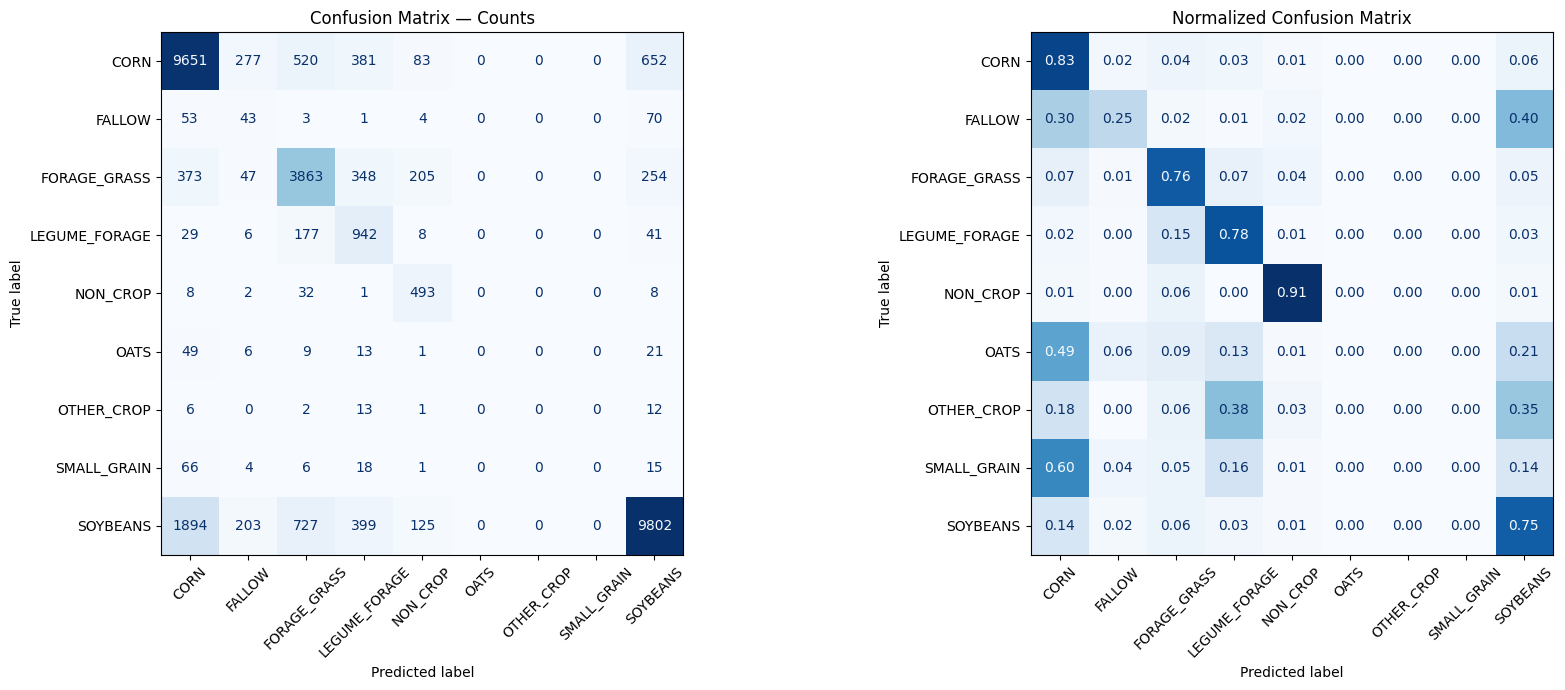

Most frequent classification errors:


,actual_crop,predicted_crop,count
42,SOYBEANS,CORN,1894
44,SOYBEANS,FORAGE_GRASS,727
4,CORN,SOYBEANS,652
1,CORN,FORAGE_GRASS,520
45,SOYBEANS,LEGUME_FORAGE,399
2,CORN,LEGUME_FORAGE,381
10,FORAGE_GRASS,CORN,373
12,FORAGE_GRASS,LEGUME_FORAGE,348
0,CORN,FALLOW,277
14,FORAGE_GRASS,SOYBEANS,254


In [ ]:

# ==========================================
# FIELD SHIFT — LSTM CONFUSION MATRIX
# ==========================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Class labels
class_names = label_encoder.classes_
labels = np.arange(len(class_names))

# Calculate confusion matrix
cm = confusion_matrix(
    y_test,
    predictions,
    labels=labels
)

# Normalize by actual class support
row_sums = cm.sum(axis=1, keepdims=True)

cm_normalized = np.divide(
    cm,
    row_sums,
    out=np.zeros_like(cm, dtype=float),
    where=row_sums != 0
)

# Plot both matrices
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(
    ax=axes[0],
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False
)

axes[0].set_title("Confusion Matrix — Counts")

ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=class_names
).plot(
    ax=axes[1],
    xticks_rotation=45,
    cmap="Blues",
    values_format=".2f",
    colorbar=False
)

axes[1].set_title("Normalized Confusion Matrix")

plt.tight_layout()
plt.show()

# Save matrices
pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(
    PROCESSED_DIR / "lstm_confusion_matrix.csv"
)

pd.DataFrame(
    cm_normalized,
    index=class_names,
    columns=class_names
).to_csv(
    PROCESSED_DIR / "lstm_confusion_matrix_normalized.csv"
)

# Find the most frequent classification errors
error_matrix = cm.copy()
np.fill_diagonal(error_matrix, 0)

error_pairs = []

for i, actual in enumerate(class_names):
    for j, predicted in enumerate(class_names):
        if error_matrix[i, j] > 0:
            error_pairs.append({
                "actual_crop": actual,
                "predicted_crop": predicted,
                "count": int(error_matrix[i, j])
            })

error_pairs = pd.DataFrame(error_pairs)

error_pairs = error_pairs.sort_values(
    "count",
    ascending=False
)

print("Most frequent classification errors:")
display(error_pairs.head(15))


In [ ]:

# ==========================================
# FIELD SHIFT — CROP KNOWLEDGE BASE v1
# Soil pH suitability screening
# ==========================================

import pandas as pd
import numpy as np

# Iowa State Extension pH reference values
crop_profiles = pd.DataFrame([
    {"crop_group": "CORN", "pH_sufficient": 6.5,
     "reference": "Iowa State Extension"},
    {"crop_group": "SOYBEANS", "pH_sufficient": 6.5,
     "reference": "Iowa State Extension"},
    {"crop_group": "FORAGE_GRASS", "pH_sufficient": 6.0,
     "reference": "Iowa State Extension"},
    {"crop_group": "LEGUME_FORAGE", "pH_sufficient": 6.0,
     "reference": "Other forage legumes; alfalfa may require 6.9"},
    {"crop_group": "OATS", "pH_sufficient": np.nan,
     "reference": "No Iowa-specific threshold assigned"},
    {"crop_group": "SMALL_GRAIN", "pH_sufficient": np.nan,
     "reference": "Threshold not assigned"},
])

# Save the knowledge base
crop_profiles.to_csv(
    PROCESSED_DIR / "crop_knowledge_base_v1.csv",
    index=False
)

display(crop_profiles)

# ==========================================
# Build latest soil record for each site
# ==========================================

latest_sites = (
    sequence_data
    .sort_values(["county_name", "pixel_id", "year"])
    .groupby(["county_name", "pixel_id"], as_index=False)
    .tail(1)
    .copy()
)

soil_columns = [
    "county_name", "pixel_id", "year",
    "ph1to1h2o_r", "om_r", "awc_r",
    "sandtotal_r", "silttotal_r", "claytotal_r"
]

latest_sites = latest_sites[soil_columns].copy()

# Candidate crops for preliminary assessment
candidates = crop_profiles[
    crop_profiles["pH_sufficient"].notna()
].copy()

# Cross join each site with candidate crops
latest_sites["_key"] = 1
candidates["_key"] = 1

soil_candidate_scores = latest_sites.merge(
    candidates,
    on="_key"
).drop(columns="_key")

# pH screening score:
# 100 = meets reference pH
# Lower score = increasingly below reference
def calculate_ph_score(row):
    ph = row["ph1to1h2o_r"]
    target = row["pH_sufficient"]

    if pd.isna(ph) or pd.isna(target):
        return np.nan

    return round(
        max(0, min(100, 100 - max(0, target - ph) * 50)),
        2
    )

soil_candidate_scores["soil_ph_score"] = (
    soil_candidate_scores.apply(
        calculate_ph_score,
        axis=1
    )
)

soil_candidate_scores["ph_status"] = np.where(
    soil_candidate_scores["ph1to1h2o_r"]
    >= soil_candidate_scores["pH_sufficient"],
    "Meets reference",
    "Below reference"
)

soil_candidate_scores.to_csv(
    PROCESSED_DIR / "soil_candidate_scores_v1.csv",
    index=False
)

print("Latest soil sites:", len(latest_sites))
print("Candidate assessments:", len(soil_candidate_scores))

display(
    soil_candidate_scores[
        [
            "county_name", "pixel_id", "crop_group",
            "ph1to1h2o_r", "pH_sufficient",
            "soil_ph_score", "ph_status"
        ]
    ].head(12)
)


,crop_group,pH_sufficient,reference
0,CORN,6.5,Iowa State Extension
1,SOYBEANS,6.5,Iowa State Extension
2,FORAGE_GRASS,6.0,Iowa State Extension
3,LEGUME_FORAGE,6.0,Other forage legumes; alfalfa may require 6.9
4,OATS,NaN,No Iowa-specific threshold assigned
5,SMALL_GRAIN,NaN,Threshold not assigned


Latest soil sites: 19984
Candidate assessments: 79936


,county_name,pixel_id,crop_group,ph1to1h2o_r,pH_sufficient,soil_ph_score,ph_status
0,Allamakee,0,CORN,7.520000,6.5,100.0,Meets reference
1,Allamakee,0,SOYBEANS,7.520000,6.5,100.0,Meets reference
2,Allamakee,0,FORAGE_GRASS,7.520000,6.0,100.0,Meets reference
3,Allamakee,0,LEGUME_FORAGE,7.520000,6.0,100.0,Meets reference
4,Allamakee,1,CORN,6.547719,6.5,100.0,Meets reference
5,Allamakee,1,SOYBEANS,6.547719,6.5,100.0,Meets reference
6,Allamakee,1,FORAGE_GRASS,6.547719,6.0,100.0,Meets reference
7,Allamakee,1,LEGUME_FORAGE,6.547719,6.0,100.0,Meets reference
8,Allamakee,2,CORN,6.510000,6.5,100.0,Meets reference
9,Allamakee,2,SOYBEANS,6.510000,6.5,100.0,Meets reference


In [ ]:

# ==========================================
# FIELD SHIFT — CROP ROTATION ASSESSMENT v1
# ==========================================

# Get the latest observed crop history per site
history = sequence_data.sort_values(
    ["county_name", "pixel_id", "year"]
).copy()

site_history = []

for (county, pixel), group in history.groupby(
    ["county_name", "pixel_id"]
):
    group = group.sort_values("year")

    last = group.iloc[-1]
    previous = group.iloc[-2] if len(group) >= 2 else None

    site_history.append({
        "county_name": county,
        "pixel_id": pixel,
        "last_observed_year": int(last["year"]),
        "previous_crop_group": (
            last["crop_group"]
        ),
        "crop_two_seasons_ago": (
            previous["crop_group"]
            if previous is not None else None
        )
    })

site_history = pd.DataFrame(site_history)

# Attach historical crop information to candidate assessments
rotation_assessment = soil_candidate_scores.merge(
    site_history,
    on=["county_name", "pixel_id"],
    how="left"
)

# Initial transparent rotation screening heuristic
def rotation_score(row):

    candidate = row["crop_group"]
    previous = row["previous_crop_group"]
    two_years_ago = row["crop_two_seasons_ago"]

    if pd.isna(previous):
        return 70

    # Avoid recommending the same annual crop repeatedly
    if candidate == previous and candidate in [
        "CORN", "SOYBEANS"
    ]:
        return 50

    # Corn-soybean alternation
    if (
        candidate == "CORN"
        and previous == "SOYBEANS"
    ):
        return 100

    if (
        candidate == "SOYBEANS"
        and previous == "CORN"
    ):
        return 100

    # Repeated annual crop in the two previous seasons
    if (
        candidate == previous
        and two_years_ago == previous
    ):
        return 35

    return 75


rotation_assessment["rotation_score"] = (
    rotation_assessment.apply(
        rotation_score,
        axis=1
    )
)

# Combine the two preliminary screening dimensions
rotation_assessment["preliminary_score"] = (
    0.5 * rotation_assessment["soil_ph_score"]
    + 0.5 * rotation_assessment["rotation_score"]
)

rotation_assessment.to_csv(
    PROCESSED_DIR / "crop_rotation_assessment_v1.csv",
    index=False
)

print("Rotation assessment shape:", rotation_assessment.shape)

print("\nRotation score distribution:")
display(
    rotation_assessment["rotation_score"].value_counts()
    .sort_index()
)

print("\nSample assessments:")
display(
    rotation_assessment[
        [
            "county_name",
            "pixel_id",
            "previous_crop_group",
            "crop_group",
            "soil_ph_score",
            "rotation_score",
            "preliminary_score"
        ]
    ].head(15)
)


Rotation assessment shape: (79936, 19)

Rotation score distribution:


,count
rotation_score,
35,488
50,18511
75,42426
100,18511



Sample assessments:


,county_name,pixel_id,previous_crop_group,crop_group,soil_ph_score,rotation_score,preliminary_score
0,Allamakee,0,CORN,CORN,100.0,50,75.0
1,Allamakee,0,CORN,SOYBEANS,100.0,100,100.0
2,Allamakee,0,CORN,FORAGE_GRASS,100.0,75,87.5
3,Allamakee,0,CORN,LEGUME_FORAGE,100.0,75,87.5
4,Allamakee,1,CORN,CORN,100.0,50,75.0
5,Allamakee,1,CORN,SOYBEANS,100.0,100,100.0
6,Allamakee,1,CORN,FORAGE_GRASS,100.0,75,87.5
7,Allamakee,1,CORN,LEGUME_FORAGE,100.0,75,87.5
8,Allamakee,2,CORN,CORN,100.0,50,75.0
9,Allamakee,2,CORN,SOYBEANS,100.0,100,100.0


In [ ]:

# ==========================================
# FIELD SHIFT — FUTURE LSTM PREDICTIONS
# ==========================================

future_seq = []
future_soil = []
future_sites = []

for (county, pixel), group in sequence_data.groupby(
    ["county_name", "pixel_id"]
):
    group = group.sort_values("year").reset_index(drop=True)

    if len(group) < SEQ_LEN:
        continue

    last_three = group.tail(SEQ_LEN)

    years = last_three["year"].to_numpy()

    if not np.all(np.diff(years) == 1):
        continue

    # Historical crop one-hot encoding
    crop_ids = [
        crop_to_index[c]
        for c in last_three["crop_group"]
    ]

    crop_onehot = np.eye(
        len(crop_categories),
        dtype=np.float32
    )[crop_ids]

    # Historical climate
    climate_values = last_three[
        climate_features
    ].to_numpy(dtype=np.float32)

    sequence = np.concatenate(
        [crop_onehot, climate_values],
        axis=1
    )

    soil_vector = last_three.iloc[-1][
        soil_features
    ].to_numpy(dtype=np.float32)

    future_seq.append(sequence)
    future_soil.append(soil_vector)

    future_sites.append({
        "county_name": county,
        "pixel_id": pixel,
        "history_last_year": int(last_three.iloc[-1]["year"])
    })

future_seq = np.asarray(future_seq, dtype=np.float32)
future_soil = np.asarray(future_soil, dtype=np.float32)

# Apply the same training scalers
future_seq_scaled = future_seq.copy()

future_seq_scaled[:, :, n_crop_features:] = (
    climate_scaler.transform(
        future_seq[:, :, n_crop_features:].reshape(
            -1, n_climate_features
        )
    ).reshape(
        len(future_seq), SEQ_LEN, n_climate_features
    )
)

future_soil_scaled = soil_scaler.transform(
    future_soil
).astype(np.float32)

# Predict next-season historical crop probabilities
future_probabilities = model.predict(
    [future_seq_scaled, future_soil_scaled],
    verbose=0
)

future_sites_df = pd.DataFrame(future_sites)

# Create one probability column per class
for i, crop in enumerate(label_encoder.classes_):
    future_sites_df[f"lstm_prob_{crop}"] = (
        future_probabilities[:, i]
    )

print("Future prediction sites:", len(future_sites_df))
print("Prediction matrix:", future_probabilities.shape)

display(future_sites_df.head())

# Save predictions
future_sites_df.to_csv(
    PROCESSED_DIR / "lstm_future_crop_probabilities.csv",
    index=False
)

# Merge LSTM probabilities into crop assessments
recommendation_candidates = rotation_assessment.merge(
    future_sites_df,
    on=["county_name", "pixel_id"],
    how="left"
)

print(
    "Recommendation candidates:",
    recommendation_candidates.shape
)

display(
    recommendation_candidates[
        [
            "county_name",
            "pixel_id",
            "crop_group",
            "previous_crop_group",
            "soil_ph_score",
            "rotation_score",
            "preliminary_score",
            "lstm_prob_CORN",
            "lstm_prob_SOYBEANS"
        ]
    ].head(12)
)

recommendation_candidates.to_csv(
    PROCESSED_DIR / "field_shift_candidates_with_lstm.csv",
    index=False
)


Future prediction sites: 19984
Prediction matrix: (19984, 9)


,county_name,pixel_id,history_last_year,lstm_prob_CORN,lstm_prob_FALLOW,lstm_prob_FORAGE_GRASS,lstm_prob_LEGUME_FORAGE,lstm_prob_NON_CROP,lstm_prob_OATS,lstm_prob_OTHER_CROP,lstm_prob_SMALL_GRAIN,lstm_prob_SOYBEANS
0,Allamakee,0,2025,0.335865,0.326378,0.020698,0.115576,0.026641,0.096196,0.004541,0.012055,0.062049
1,Allamakee,1,2025,0.135801,0.013244,0.019774,0.091937,0.008347,0.082165,0.009328,0.018433,0.620971
2,Allamakee,2,2025,0.365983,0.089234,0.020416,0.131356,0.011788,0.173156,0.012648,0.035644,0.159775
3,Allamakee,3,2025,0.119311,0.011230,0.216262,0.214603,0.043720,0.200886,0.014457,0.041136,0.138394
4,Allamakee,4,2025,0.435730,0.058023,0.019305,0.208164,0.010626,0.118158,0.016152,0.034072,0.099771


Recommendation candidates: (79936, 29)


,county_name,pixel_id,crop_group,previous_crop_group,soil_ph_score,rotation_score,preliminary_score,lstm_prob_CORN,lstm_prob_SOYBEANS
0,Allamakee,0,CORN,CORN,100.0,50,75.0,0.335865,0.062049
1,Allamakee,0,SOYBEANS,CORN,100.0,100,100.0,0.335865,0.062049
2,Allamakee,0,FORAGE_GRASS,CORN,100.0,75,87.5,0.335865,0.062049
3,Allamakee,0,LEGUME_FORAGE,CORN,100.0,75,87.5,0.335865,0.062049
4,Allamakee,1,CORN,CORN,100.0,50,75.0,0.135801,0.620971
5,Allamakee,1,SOYBEANS,CORN,100.0,100,100.0,0.135801,0.620971
6,Allamakee,1,FORAGE_GRASS,CORN,100.0,75,87.5,0.135801,0.620971
7,Allamakee,1,LEGUME_FORAGE,CORN,100.0,75,87.5,0.135801,0.620971
8,Allamakee,2,CORN,CORN,100.0,50,75.0,0.365983,0.159775
9,Allamakee,2,SOYBEANS,CORN,100.0,100,100.0,0.365983,0.159775


In [ ]:

# ==========================================
# FIELD SHIFT — HYBRID CROP RANKING v1
# ==========================================

ranked_candidates = recommendation_candidates.copy()

# Get the LSTM probability of the candidate crop itself
ranked_candidates["candidate_lstm_probability"] = (
    ranked_candidates.apply(
        lambda row: row[
            f"lstm_prob_{row['crop_group']}"
        ],
        axis=1
    )
)

# Convert probability to 0-100 scale
ranked_candidates["lstm_score"] = (
    ranked_candidates["candidate_lstm_probability"] * 100
)

# Preliminary weighted score
ranked_candidates["hybrid_score"] = (
    0.40 * ranked_candidates["lstm_score"]
    + 0.30 * ranked_candidates["soil_ph_score"]
    + 0.30 * ranked_candidates["rotation_score"]
)

# Rank candidates within each site
ranked_candidates["candidate_rank"] = (
    ranked_candidates.groupby(
        ["county_name", "pixel_id"]
    )["hybrid_score"]
    .rank(method="first", ascending=False)
    .astype(int)
)

# Sort and extract top 3 recommendations per site
ranked_candidates = ranked_candidates.sort_values(
    ["county_name", "pixel_id", "candidate_rank"]
)

top_recommendations = ranked_candidates[
    ranked_candidates["candidate_rank"] <= 3
].copy()

# Save outputs
ranked_candidates.to_csv(
    PROCESSED_DIR / "field_shift_all_ranked_candidates_v1.csv",
    index=False
)

top_recommendations.to_csv(
    PROCESSED_DIR / "field_shift_top3_recommendations_v1.csv",
    index=False
)

print("All ranked candidates:", ranked_candidates.shape)
print("Top recommendations:", top_recommendations.shape)

print("\nSample top recommendations:")
display(
    top_recommendations[
        [
            "county_name",
            "pixel_id",
            "crop_group",
            "candidate_lstm_probability",
            "soil_ph_score",
            "rotation_score",
            "hybrid_score",
            "candidate_rank"
        ]
    ].head(15)
)

print("\nMost frequently ranked first:")
display(
    top_recommendations[
        top_recommendations["candidate_rank"] == 1
    ]["crop_group"].value_counts()
)


All ranked candidates: (79936, 33)
Top recommendations: (59952, 33)

Sample top recommendations:


,county_name,pixel_id,crop_group,candidate_lstm_probability,soil_ph_score,rotation_score,hybrid_score,candidate_rank
1,Allamakee,0,SOYBEANS,0.062049,100.0,100,62.481966,1
0,Allamakee,0,CORN,0.335865,100.0,50,58.434606,2
3,Allamakee,0,LEGUME_FORAGE,0.115576,100.0,75,57.123054,3
5,Allamakee,1,SOYBEANS,0.620971,100.0,100,84.838841,1
7,Allamakee,1,LEGUME_FORAGE,0.091937,100.0,75,56.177471,2
6,Allamakee,1,FORAGE_GRASS,0.019774,100.0,75,53.290949,3
9,Allamakee,2,SOYBEANS,0.159775,100.0,100,66.390985,1
8,Allamakee,2,CORN,0.365983,100.0,50,59.639328,2
11,Allamakee,2,LEGUME_FORAGE,0.131356,100.0,75,57.754223,3
14,Allamakee,3,FORAGE_GRASS,0.216262,100.0,75,61.150489,1



Most frequently ranked first:


,count
crop_group,
SOYBEANS,9289
CORN,7822
LEGUME_FORAGE,2788
FORAGE_GRASS,85


In [ ]:

# ==========================================
# FIELD SHIFT — ECONOMIC INTEGRATION v1
# ==========================================

# Map model crop groups to NASS crop names
crop_name_map = {
    "CORN": "Corn",
    "SOYBEANS": "Soybeans",
    "OATS": "Oats"
}

# Prepare historical county-level gross revenue
economic = revenue_data.copy()

economic["crop_group"] = (
    economic["crop"].astype(str).str.upper()
    .map({
        "CORN": "CORN",
        "SOYBEANS": "SOYBEANS",
        "OATS": "OATS"
    })
)

economic = economic.dropna(
    subset=["crop_group", "gross_revenue_usd_acre"]
)

county_revenue = (
    economic.groupby(["county", "crop_group"])
    ["gross_revenue_usd_acre"]
    .mean()
    .reset_index()
    .rename(columns={
        "county": "county_name",
        "gross_revenue_usd_acre": "avg_gross_revenue"
    })
)

# Attach economic data to all crop candidates
economic_candidates = ranked_candidates.merge(
    county_revenue,
    on=["county_name", "crop_group"],
    how="left"
)

# Normalize revenue within each county
def normalize_revenue(group):
    values = group["avg_gross_revenue"]
    valid = values.dropna()

    group["economic_score"] = np.nan

    if len(valid) == 0:
        return group

    low = valid.min()
    high = valid.max()

    if high == low:
        group.loc[values.notna(), "economic_score"] = 50
    else:
        group["economic_score"] = (
            (values - low) / (high - low) * 100
        )

    return group

economic_candidates = (
    economic_candidates.groupby(
        "county_name", group_keys=False
    ).apply(normalize_revenue)
)

economic_candidates["economic_data_available"] = (
    economic_candidates["economic_score"].notna()
)

# Weighted score:
# LSTM 30%, Soil 20%, Rotation 20%, Economics 30%
# Missing economic data is excluded and remaining weights
# are proportionally renormalized.

components = {
    "lstm_score": 0.30,
    "soil_ph_score": 0.20,
    "rotation_score": 0.20,
    "economic_score": 0.30
}

weighted_sum = 0
available_weight = 0

for column, weight in components.items():
    valid = economic_candidates[column].notna()
    weighted_sum += (
        economic_candidates[column].fillna(0) * weight
    )
    available_weight += valid.astype(float) * weight

economic_candidates["final_score"] = (
    weighted_sum / available_weight * 1.0
)

# Rank within each site
economic_candidates["final_rank"] = (
    economic_candidates.groupby(
        ["county_name", "pixel_id"]
    )["final_score"]
    .rank(method="first", ascending=False)
    .astype(int)
)

economic_candidates = economic_candidates.sort_values(
    ["county_name", "pixel_id", "final_rank"]
)

final_top3 = economic_candidates[
    economic_candidates["final_rank"] <= 3
].copy()

# Save results
economic_candidates.to_csv(
    PROCESSED_DIR / "field_shift_economic_rankings_v1.csv",
    index=False
)

final_top3.to_csv(
    PROCESSED_DIR / "field_shift_final_top3_v1.csv",
    index=False
)

print("Economic records matched:",
      economic_candidates["economic_data_available"].sum())

print("Candidates without economic data:",
      (~economic_candidates["economic_data_available"]).sum())

print("\nFinal top recommendations:")
display(
    final_top3[
        [
            "county_name", "pixel_id", "crop_group",
            "candidate_lstm_probability",
            "soil_ph_score", "rotation_score",
            "avg_gross_revenue", "economic_score",
            "economic_data_available",
            "final_score", "final_rank"
        ]
    ].head(15)
)

print("\nMost frequently ranked first:")
display(
    final_top3[final_top3["final_rank"] == 1]
    ["crop_group"].value_counts()
)


/tmp/ipykernel_836/1401937159.py:71: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ).apply(normalize_revenue)


Economic records matched: 39968
Candidates without economic data: 39968

Final top recommendations:


,county_name,pixel_id,crop_group,candidate_lstm_probability,soil_ph_score,rotation_score,avg_gross_revenue,economic_score,economic_data_available,final_score,final_rank
1,Allamakee,0,CORN,0.335865,100.0,50,861.432091,100.0,True,70.075954,1
2,Allamakee,0,LEGUME_FORAGE,0.115576,100.0,75,NaN,NaN,False,54.953272,2
3,Allamakee,0,FORAGE_GRASS,0.020698,100.0,75,NaN,NaN,False,50.887064,3
7,Allamakee,1,CORN,0.135801,100.0,50,861.432091,100.0,True,64.074044,1
4,Allamakee,1,SOYBEANS,0.620971,100.0,100,615.189600,0.0,True,58.629131,2
5,Allamakee,1,LEGUME_FORAGE,0.091937,100.0,75,NaN,NaN,False,53.940148,3
9,Allamakee,2,CORN,0.365983,100.0,50,861.432091,100.0,True,70.979496,1
10,Allamakee,2,LEGUME_FORAGE,0.131356,100.0,75,NaN,NaN,False,55.629525,2
11,Allamakee,2,FORAGE_GRASS,0.020416,100.0,75,NaN,NaN,False,50.874960,3
15,Allamakee,3,CORN,0.119311,84.2,50,861.432091,100.0,True,60.419344,1



Most frequently ranked first:


,count
crop_group,
CORN,15096
SOYBEANS,3250
LEGUME_FORAGE,1628
FORAGE_GRASS,10


In [ ]:

# =====================================================
# FIELD SHIFT — RECURSIVE 3-SEASON LSTM FORECAST
# =====================================================

future_climate_by_county = (
    sequence_data.groupby("county_name")[climate_features]
    .mean()
)

multi_step_results = []

for (county, pixel), group in sequence_data.groupby(
    ["county_name", "pixel_id"]
):
    group = group.sort_values("year").reset_index(drop=True)

    if len(group) < SEQ_LEN:
        continue

    last_three = group.tail(SEQ_LEN)

    years = last_three["year"].to_numpy()

    if not np.all(np.diff(years) == 1):
        continue

    # Historical crop + climate sequence
    crop_ids = [
        crop_to_index[c]
        for c in last_three["crop_group"]
    ]

    crop_onehot = np.eye(
        len(crop_categories), dtype=np.float32
    )[crop_ids]

    climate_values = last_three[
        climate_features
    ].to_numpy(dtype=np.float32)

    rolling_sequence = np.concatenate(
        [crop_onehot, climate_values], axis=1
    )

    # Static soil features
    soil_vector = last_three.iloc[-1][
        soil_features
    ].to_numpy(dtype=np.float32)

    soil_scaled = soil_scaler.transform(
        soil_vector.reshape(1, -1)
    ).astype(np.float32)

    # Assumed future climate: county historical average
    future_climate = future_climate_by_county.loc[
        county
    ].to_numpy(dtype=np.float32)

    last_year = int(last_three.iloc[-1]["year"])

    # Recursive forecasting: 2026, 2027, 2028
    for step in range(1, 4):

        # Scale climate using the original training scaler
        seq_scaled = rolling_sequence.copy()

        seq_scaled[:, n_crop_features:] = (
            climate_scaler.transform(
                rolling_sequence[:, n_crop_features:]
            )
        )

        seq_input = seq_scaled.reshape(
            1, SEQ_LEN, -1
        ).astype(np.float32)

        probabilities = model.predict(
            [seq_input, soil_scaled],
            verbose=0
        )[0]

        predicted_index = int(np.argmax(probabilities))
        predicted_crop = label_encoder.classes_[predicted_index]

        forecast_year = last_year + step

        result = {
            "county_name": county,
            "pixel_id": pixel,
            "forecast_year": forecast_year,
            "forecast_step": step,
            "predicted_crop": predicted_crop,
            "climate_scenario": "Historical county average"
        }

        for i, crop in enumerate(label_encoder.classes_):
            result[f"lstm_prob_{crop}"] = float(probabilities[i])

        multi_step_results.append(result)

        # Feed predicted crop into the next time step
        next_crop_onehot = np.zeros(
            len(crop_categories), dtype=np.float32
        )
        next_crop_onehot[crop_to_index[predicted_crop]] = 1.0

        next_step = np.concatenate([
            next_crop_onehot,
            future_climate
        ])

        rolling_sequence = np.vstack([
            rolling_sequence[1:],
            next_step
        ])


# Final forecast table
multi_season_forecast = pd.DataFrame(multi_step_results)

multi_season_forecast.to_csv(
    PROCESSED_DIR / "field_shift_3_season_lstm_forecast.csv",
    index=False
)

print("Forecast rows:", len(multi_season_forecast))
print("Unique sites:", multi_season_forecast["pixel_id"].nunique())
print("\nForecast years:")
display(
    multi_season_forecast.groupby("forecast_year").size()
)

print("\nPredicted crop distribution by season:")
display(
    multi_season_forecast.groupby(
        ["forecast_year", "predicted_crop"]
    ).size().unstack(fill_value=0)
)

display(multi_season_forecast.head(10))


KeyboardInterrupt: 

In [ ]:
print("rotation:", "rotation" in globals())
print("sequence_data:", "sequence_data" in globals())
print("model:", "model" in globals())
print("climate_scaler:", "climate_scaler" in globals())
print("soil_scaler:", "soil_scaler" in globals())
print("future_sites_df:", "future_sites_df" in globals())

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

print("الملفات الموجودة في Google Drive:")
for item in os.listdir('/content/drive/MyDrive'):
    print(item)

In [ ]:
import os

base_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(base_path):
    # تجاهل المجلدات غير المهمة
    dirs[:] = [d for d in dirs if not d.startswith(".")]

    for file in files:
        if any(word in file.lower() for word in [
            "field", "shift", "rotation", "lstm", "model",
            "soil", "climate", "cdl", "nass"
        ]) or file.endswith((".ipynb", ".keras", ".h5", ".pkl", ".csv")):
            print(os.path.join(root, file))

In [ ]:
import os

base_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(base_path):
    dirs[:] = [d for d in dirs if not d.startswith(".")]

    if root.count(os.sep) - base_path.count(os.sep) <= 2:
        print(f"\n📁 {root}")
        for d in dirs:
            print(f"   📂 {d}")
        for f in files:
            print(f"   📄 {f}")

## 9) Quick data coverage audit

This creates a compact summary that makes it easier to see whether one county or crop has major gaps before modelling.

In [ ]:
coverage_rows = []
for row in COUNTIES.to_dict('records'):
    county = row['county_name']
    coverage_rows.append({
        'county_name':county,
        'county_fips':row['county_fips'],
        'cdl_years_downloaded':len(cdl_paths.get(county, {})),
        'power_rows':int((power_all['county_name']==county).sum()) if not power_all.empty else 0,
        'ssurgo_rows':int((ssurgo_all['county_name']==county).sum()) if not ssurgo_all.empty else 0,
        'nass_yield_rows':int((nass_yields['county_name_query']==county).sum()) if not nass_yields.empty else 0,
    })
coverage = pd.DataFrame(coverage_rows)
coverage.to_csv(PROCESSED_DIR / 'county_data_coverage_audit.csv', index=False)
display(coverage)

## 10) Save a compact results bundle

The default ZIP includes processed CSV outputs and small JSON metadata, but **excludes the original CDL GeoTIFFs** to avoid creating a huge download. The TIFFs remain in `/content/field_shift_data/raw/cdl/` in the Colab runtime. Set `INCLUDE_CDL_TIFFS_IN_ZIP = True` only if you explicitly need the raw rasters in the downloaded archive.

In [ ]:
from google.colab import files

INCLUDE_CDL_TIFFS_IN_ZIP = False
ZIP_PATH = Path('/content/field_shift_5_counties_results.zip')

with zipfile.ZipFile(ZIP_PATH, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for path in PROJECT_DIR.rglob('*'):
        if not path.is_file():
            continue
        if not INCLUDE_CDL_TIFFS_IN_ZIP and path.suffix.lower() in {'.tif', '.tiff'}:
            continue
        zf.write(path, arcname=path.relative_to(PROJECT_DIR))

print('Created:', ZIP_PATH, '| size MB:', round(ZIP_PATH.stat().st_size/1e6, 2))
files.download(str(ZIP_PATH))

## What to send back after running

Please send the `field_shift_5_counties_results.zip` or these files first:

- `county_data_coverage_audit.csv`
- `cdl_sampled_crop_class_shares.csv`
- `cdl_sampled_pixel_crop_history.csv` (first rows + shape if too large)
- `cdl_sampled_crop_sequences_wide.csv` (one row per sampled pixel, years as columns)
- `ssurgo_horizons_components_all_counties.csv` (first rows + row counts by county)
- `nasa_power_daily_all_counties.csv` (first rows + date coverage by county)
- `nass_county_crop_yields.csv` if API key was used
- `ams_iowa_cash_grain_bids.csv` if API key was used

**Do not train the LSTM yet.** First we will inspect whether all five counties have enough annual crop-history coverage, whether the soil queries return rows, which crops have county yield records, and how the climate and market data align. Then we will build the modelling table and decide the correct spatial holdout county.